# CS781 Capstone · Phase 5 · Legal Statute Identification (LSI)

In [1]:
import os, sys, subprocess, json, glob, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "regex", "huggingface_hub"], check=False)
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
os.makedirs(f"{WORK}/p5lsi/phase1_models", exist_ok=True); os.makedirs(f"{WORK}/tests", exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
import torch
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)] or "NONE (enable GPU!)",
      "| CPUs:", os.cpu_count())

torch 2.11.0+cu128 | GPUs: ['Tesla T4', 'Tesla T4'] | CPUs: 4


## Pipeline code (written to `p5lsi/`; nothing to edit)

In [2]:
%%writefile {WORK}/p5lsi/phase1_models/arch_a.py
"""Architecture A: decoder-only LLaMA-style (GQA, RoPE, SwiGLU).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (decoder-only-fine-tuned.ipynb / decoder-only-transformer-llama-style.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class GQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd = n_head, n_kv_head, d_model // n_head
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        if self.n_kv != self.n_head:
            rep = self.n_head // self.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_head, n_kv_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class LlamaLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=12, n_head=10, n_kv_head=2, d_model=640,
                 ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[LlamaLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = LlamaLM

Writing /kaggle/working/p5lsi/phase1_models/arch_a.py


In [3]:
%%writefile {WORK}/p5lsi/phase1_models/arch_b.py
"""Architecture B: encoder-decoder.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (B/notebookc976077ad3.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class SelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, key_mask=None, causal=False, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        mask = None if key_mask is None else key_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal and T > 1 and mask is None,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class CrossAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        self.n_head, self.hd = n_head, d_model // n_head
        self.q = nn.Linear(d_model, d_model, bias=bias)
        self.kv = nn.Linear(d_model, 2 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, memory, mem_mask, cache=None):
        B, T, C = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        if cache is not None and "ck" in cache:
            k, v = cache["ck"], cache["cv"]
        else:
            S = memory.size(1)
            k, v = self.kv(memory).view(B, S, 2, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
            if cache is not None:
                cache["ck"], cache["cv"] = k, v
        mask = None if mem_mask is None else mem_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = SelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, key_mask):
        x = x + self.attn(self.norm1(x), rope, 0, key_mask=key_mask, causal=False)
        return x + self.ffn(self.norm2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = RMSNorm(d_model), RMSNorm(d_model), RMSNorm(d_model)
        self.self_attn = SelfAttention(d_model, n_head, dropout, bias)
        self.cross_attn = CrossAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, memory, mem_mask, pos0=0, cache=None):
        x = x + self.self_attn(self.norm1(x), rope, pos0, causal=True, cache=cache)
        x = x + self.cross_attn(self.norm2(x), memory, mem_mask, cache=cache)
        return x + self.ffn(self.norm3(x))

class EncDecLM(nn.Module):
    def __init__(self, vocab_size, enc_block, dec_block, pad_id=None, n_enc_layer=6, n_dec_layer=6,
                 n_head=9, d_model=576, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EncDecLM] ignoring unknown config keys: {sorted(kw)}")
        self.enc_block, self.dec_block, self.pad_id = enc_block, dec_block, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        hd = d_model // n_head
        self.enc_rope = RotaryEmbedding(hd, enc_block, rope_theta)
        self.dec_rope = RotaryEmbedding(hd, dec_block, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_enc_layer)])
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_dec_layer)])
        self.enc_norm, self.dec_norm = RMSNorm(d_model), RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_enc_layer + n_dec_layer)
        self.lm_head.weight = self.tok_emb.weight

    def encode(self, src, src_mask=None):
        assert src.size(1) <= self.enc_block, f"source length {src.size(1)} > enc_block {self.enc_block}"
        if src_mask is not None and bool(src_mask.all()):
            src_mask = None
        x = self.drop(self.tok_emb(src))
        for blk in self.enc_blocks:
            x = blk(x, self.enc_rope, src_mask)
        return self.enc_norm(x)

    def decode(self, dec_in, memory, mem_mask=None, pos0=0, caches=None, last_only=False):
        assert pos0 + dec_in.size(1) <= self.dec_block, f"decoder position {pos0 + dec_in.size(1)} > dec_block"
        if mem_mask is not None and bool(mem_mask.all()):
            mem_mask = None
        x = self.drop(self.tok_emb(dec_in))
        for i, blk in enumerate(self.dec_blocks):
            x = blk(x, self.dec_rope, memory, mem_mask, pos0, None if caches is None else caches[i])
        x = self.dec_norm(x)
        if last_only:
            x = x[:, -1:]
        return self.lm_head(x)

    def forward(self, src, src_mask, dec_in, targets=None):
        memory = self.encode(src, src_mask)
        logits = self.decode(dec_in, memory, src_mask)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EncDecLM

Writing /kaggle/working/p5lsi/phase1_models/arch_b.py


In [4]:
%%writefile {WORK}/p5lsi/phase1_models/arch_c.py
"""Architecture C: encoder/hybrid prefix-LM + MLM (UniLM-style).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (C/encoder-hybrid.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class HybridSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, attn_mask=None, causal=True, pos0=0, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                           is_causal=causal and attn_mask is None and T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = HybridSelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, attn_mask, causal, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, attn_mask, causal, pos0, cache)
        return x + self.ffn(self.norm2(x))

class HybridLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=10, n_head=10, d_model=640, ffn_mult=8 / 3,
                 dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, n_segments=3, **kw):
        super().__init__()
        if kw:
            print(f"[HybridLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.seg_emb = nn.Embedding(n_segments, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        nn.init.zeros_(self.seg_emb.weight)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def hybrid_mask(prefix_len, T):
        pos = torch.arange(T, device=prefix_len.device)
        in_prefix = pos[None, None, :] < prefix_len[:, None, None]
        causal = pos[None, :, None] >= pos[None, None, :]
        return (in_prefix | causal)[:, None]

    def forward(self, idx, prefix_len=None, seg=None, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        if prefix_len is None:
            prefix_len = torch.zeros(B, dtype=torch.long, device=idx.device)
        prefix_len = prefix_len.to(idx.device).long().clamp(0, T)
        if bool((prefix_len == 0).all()):
            attn_mask, causal = None, True
        elif bool((prefix_len == T).all()):
            attn_mask, causal = None, False
        else:
            attn_mask, causal = self.hybrid_mask(prefix_len, T), False
        if seg is None:
            seg = (torch.arange(T, device=idx.device)[None, :] >= prefix_len[:, None]).long()
        x = self.drop(self.tok_emb(idx) + self.seg_emb(seg))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, attn_mask, causal, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = HybridLM

Writing /kaggle/working/p5lsi/phase1_models/arch_c.py


In [5]:
%%writefile {WORK}/p5lsi/phase1_models/arch_d.py
"""Architecture D: efficient decoder, sliding-window attention + MQA.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (D/notebook7e00370b82.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class LocalMQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd, self.window = n_head, n_kv_head, d_model // n_head, window
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)
        self._mask_cache = {}

    def _block_mask(self, nb, device):
        key = (nb, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            W = self.window
            a = torch.arange(W, device=device)[:, None]
            b = torch.arange(2 * W, device=device)[None, :]
            keep = ((b > a) & (b <= a + W))[None].repeat(nb, 1, 1)
            keep[0, :, :W] = False
            m = keep[None, None].expand(1, self.n_head, nb, W, 2 * W).reshape(1, self.n_head * nb, W, 2 * W)
            self._mask_cache = {key: m}
        return m

    def _blocked(self, q, k, v):
        B, H, T, hd = q.shape
        W, Hkv = self.window, k.size(1)
        Tp = -(-T // W) * W
        if Tp != T:
            q, k, v = (F.pad(t, (0, 0, 0, Tp - T)) for t in (q, k, v))
        nb = Tp // W
        k = F.pad(k, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        v = F.pad(v, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        rep = H // Hkv
        k = k[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        v = v[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        qb = q.reshape(B, H * nb, W, hd)
        y = F.scaled_dot_product_attention(qb, k, v, attn_mask=self._block_mask(nb, q.device),
                                           dropout_p=self.dropout if self.training else 0.0)
        return y.reshape(B, H, Tp, hd)[:, :, :T]

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None and "k" in cache:
            assert T == 1, "cached decoding feeds one token at a time"
            k = torch.cat([cache["k"], k], 2)[:, :, -self.window:]
            v = torch.cat([cache["v"], v], 2)[:, :, -self.window:]
            cache["k"], cache["v"] = k, v
            rep = self.n_head // self.n_kv
            y = F.scaled_dot_product_attention(q, k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1))
        else:
            y = self._blocked(q, k, v)
            if cache is not None:
                cache["k"], cache["v"] = k[:, :, -self.window:], v[:, :, -self.window:]
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = LocalMQAttention(d_model, n_head, n_kv_head, window, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class EfficientLM(nn.Module):
    def __init__(self, vocab_size, block_size, window=256, pad_id=None, n_layer=12, n_head=10, n_kv_head=1,
                 d_model=640, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, rope_max_len=8192,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EfficientLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.window, self.pad_id, self.n_layer = block_size, window, pad_id, n_layer
        self.max_pos = max(rope_max_len, block_size)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, self.max_pos, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, window, hidden, dropout, bias)
                                     for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EfficientLM

Writing /kaggle/working/p5lsi/phase1_models/arch_d.py


In [6]:
%%writefile {WORK}/p5lsi/phase1_models/common.py
"""Shared building blocks (RMSNorm, RoPE, SwiGLU, init).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (identical in A/B/C/D notebooks, cell 19),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x, pos0=0):
        T = x.size(-2)
        assert pos0 + T <= self.cos.size(0), f"position {pos0 + T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[pos0:pos0 + T], self.sin[pos0:pos0 + T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))

def init_weights_(model, n_layer):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
    for name, p in model.named_parameters():
        if name.endswith("proj.weight"):
            nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

def lm_loss(logits, targets):
    return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

Writing /kaggle/working/p5lsi/phase1_models/common.py


In [7]:
%%writefile {WORK}/p5lsi/phase1_models/__init__.py
from .arch_a import LlamaLM
from .arch_b import EncDecLM
from .arch_c import HybridLM
from .arch_d import EfficientLM

MODEL_CLASSES = {c.__name__: c for c in (LlamaLM, EncDecLM, HybridLM, EfficientLM)}

Writing /kaggle/working/p5lsi/phase1_models/__init__.py


In [8]:
%%writefile {WORK}/p5lsi/__init__.py
"""CS781 Phase 5: Legal Statute Identification (LSI, multi-label) on the Phase-1 legal language models."""

Writing /kaggle/working/p5lsi/__init__.py


In [9]:
%%writefile {WORK}/p5lsi/tokenizer.py
"""Byte-level BPE tokenizer from Phase 1 (load-only copy) + character offsets for NER.

Phase 1 trained the merges; here we only *load* them (same ids as pretraining) and add
`encode_with_offsets`, which returns for every token the character span it covers in the original text.

Offsets are computed per pre-token: the regex gives each pre-token's char span, BPE splits the pre-token's
UTF-8 bytes into tokens, and a byte->char table maps every token's byte range back to characters.
"""
import hashlib
import json
import os
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import regex as re_u

SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

FINE_PUNCT_PATTERN = (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}{1,3}| ?[^\s\p{L}\p{N}]|\s*[\r\n]+|\s+(?!\S)|\s+""")

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

@dataclass
class Encoded:
    ids: list
    starts: list
    ends: list

class BPETokenizer:
    def __init__(self, merges, pattern, specials=SPECIAL_TOKENS, fine_punct=False):
        self.base_pattern = pattern
        self.fine_punct = fine_punct
        self.pattern = FINE_PUNCT_PATTERN if fine_punct else pattern
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in merges]
        self.specials = list(specials)
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.n_regular = base
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self.cache = {}
        self._oc, self._oc_path, self._oc_new = None, None, 0

    def fingerprint(self):
        h = hashlib.sha1(self.pattern.encode())
        h.update(json.dumps(self.merges).encode())
        return h.hexdigest()[:12]

    def enable_disk_cache(self, cache_dir):
        Path(cache_dir).mkdir(parents=True, exist_ok=True)
        self._oc_path = Path(cache_dir) / f"offsets_{self.fingerprint()}.pkl"
        self._oc = {}
        if self._oc_path.exists():
            try:
                self._oc = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                self._oc = {}
        return self

    def save_disk_cache(self):
        if self._oc is None or not self._oc_new:
            return
        disk = {}
        if self._oc_path.exists():
            try:
                disk = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                disk = {}
        disk.update(self._oc)
        tmp = self._oc_path.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(disk, open(tmp, "wb"), protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self._oc_path)
        self._oc, self._oc_new = disk, 0

    @classmethod
    def load(cls, path, fine_punct=False):
        d = json.load(open(path, encoding="utf-8"))
        return cls(d["merges"], d["pattern"], d.get("specials", SPECIAL_TOKENS), fine_punct=fine_punct)

    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode_with_offsets(self, text):
        if self._oc is not None:
            key = hashlib.sha1(text.encode("utf-8")).hexdigest()
            hit = self._oc.get(key)
            if hit is not None:
                return Encoded(hit[0].tolist(), hit[1].tolist(), hit[2].tolist())
            enc = self._encode_with_offsets(text)
            self._oc[key] = (np.asarray(enc.ids, dtype=np.int32), np.asarray(enc.starts, dtype=np.int32),
                             np.asarray(enc.ends, dtype=np.int32))
            self._oc_new += 1
            return enc
        return self._encode_with_offsets(text)

    def _encode_with_offsets(self, text):
        ids, starts, ends = [], [], []
        for m in self.pat.finditer(text):
            w, c0 = m.group(), m.start()
            wid = self._encode_word(w)
            if len(wid) == 1:
                ids.append(wid[0]); starts.append(c0); ends.append(m.end())
                continue
            b2c = []
            for ci, ch in enumerate(w):
                b2c.extend([ci] * len(ch.encode("utf-8")))
            b = 0
            for t in wid:
                nb = len(self.vocab[t])
                ids.append(t)
                starts.append(c0 + b2c[b])
                ends.append(c0 + b2c[b + nb - 1] + 1)
                b += nb
        return Encoded(ids, starts, ends)

    def decode(self, ids):
        return b"".join(self.vocab[int(i)] for i in ids if int(i) < self.n_regular).decode("utf-8", errors="replace")

Writing /kaggle/working/p5lsi/tokenizer.py


In [10]:
%%writefile {WORK}/p5lsi/data.py
"""Phase-5 data: download, load, validate, tokenise once (cached), label space, statistics.
(Phase-4 module; the binary label became a list of statute ids.)

Layout (HF dataset Exploration-Lab/CS-781-Capstone, folder Phase_5_LSI):
    Train/train.json, Train/dev.json, Test/test.json
A document is {"id": "case_001", "text": "...", "labels": [1, 7, 23]} (no labels in test.json).
The loader also accepts a dict {id: {...}}, JSON lines, a {"data": [...]} wrapper, "text" given as a list of
sentences/paragraphs, the labels under "labels"/"label"/"statutes"/..., a single id instead of a list and ids
written as strings ("7"), so a small format difference does not break it. Repeated statute ids inside one
document are removed.

The label space (the statute ids the model can predict, and the only ids ever written to prediction.json) is the
sorted union of the ids in train.json and dev.json: `label_space(data)`.

Tokenising the documents with the pure-Python Phase-1 BPE takes a few minutes, so it is done ONCE
(multiprocessing) and stored as uint16 token arrays in cache_dir; every run (and both parallel GPU jobs) reuses it.
Cached form per split: {"ids": [str], "raw_ids": [original id], "labels": [list of int] | None,
                        "tokens": [np.uint16 array], "n_chars": np.int64 array}
"""
import hashlib
import json
import os
import pickle
from collections import Counter
from pathlib import Path

import numpy as np

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_SUBDIR = "Phase_5_LSI"
SPLITS = ("train", "dev", "test")
ID_KEYS = ("id", "case_id", "doc_id", "uid", "name", "case")
TEXT_KEYS = ("text", "document", "doc", "case_text", "facts", "judgment", "content", "body")
LABEL_KEYS = ("labels", "label", "statutes", "statute_ids", "statute", "y", "target", "pred")

def download(local_dir, token=None):
    from huggingface_hub import snapshot_download
    token = token or os.environ.get("HF_TOKEN")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=local_dir, token=token,
                      allow_patterns=[f"{HF_SUBDIR}/*"])
    return Path(local_dir) / HF_SUBDIR

def find_data_dir(candidates=()):
    def ok(d):
        return (d / "Train" / "train.json").exists() and (d / "Test" / "test.json").exists()
    for c in candidates:
        if c and ok(Path(c)):
            return Path(c)
    for r in [Path(c) for c in candidates if c] + [Path("/kaggle/input")]:
        if not r.exists():
            continue
        for p in r.rglob("train.json"):
            d = p.parent.parent
            if p.parent.name == "Train" and ok(d) and ("lsi" in str(d).lower() or "phase_5" in str(d).lower()
                                                       or "phase5" in str(d).lower() or "phase-5" in str(d).lower()):
                return d
    return None

def split_path(data_dir, split):
    return Path(data_dir) / ("Test" if split == "test" else "Train") / f"{split}.json"

def _read_json(path):
    txt = Path(path).read_text(encoding="utf-8")
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return [json.loads(line) for line in txt.splitlines() if line.strip()]

def _records(raw):
    if isinstance(raw, dict):
        for k in ("data", "documents", "docs", "cases", "examples"):
            if isinstance(raw.get(k), list):
                return raw[k]
        recs = []
        for k, v in raw.items():
            if isinstance(v, dict):
                recs.append({"id": k, **v} if not any(x in v for x in ID_KEYS) else v)
            elif isinstance(v, str):
                recs.append({"id": k, "text": v})
            else:
                raise ValueError(f"unexpected value type for case {k}: {type(v)}")
        return recs
    if isinstance(raw, list):
        return raw
    raise ValueError(f"unexpected top-level JSON type {type(raw)}")

def _first(r, keys):
    for k in keys:
        if k in r and r[k] is not None:
            return k, r[k]
    return None, None

def _statute_id(v, where):
    if isinstance(v, bool) or v is None:
        raise ValueError(f"{where}: statute id {v!r} is not an integer")
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, float) and v.is_integer():
        return int(v)
    if isinstance(v, str) and v.strip().lstrip("-").isdigit():
        return int(v.strip())
    raise ValueError(f"{where}: statute id {v!r} is not an integer")

def _labels(v, where):
    if isinstance(v, str):
        t = v.strip().strip("[]")
        v = [x for x in t.replace(";", ",").split(",") if x.strip()] if t else []
    elif not isinstance(v, (list, tuple, np.ndarray)):
        v = [v]
    return sorted({_statute_id(x, where) for x in v})

def normalise_text(t):
    if isinstance(t, list):
        t = " ".join("" if x is None else str(x) for x in t)
    return " ".join(str(t).split())

def norm_case(r, where, need_label):
    if not isinstance(r, dict):
        raise ValueError(f"{where}: record is {type(r)}, expected an object")
    _, rid = _first(r, ID_KEYS)
    _, text = _first(r, TEXT_KEYS)
    lk, lab = _first(r, LABEL_KEYS)
    if rid is None:
        raise ValueError(f"{where}: case without an id field: keys {sorted(r)}")
    if text is None:
        raise ValueError(f"{where}: case {rid} has no text field: keys {sorted(r)}")
    if need_label and lab is None:
        raise ValueError(f"{where}: case {rid} has no label field: keys {sorted(r)}")
    return {"id": str(rid), "raw_id": rid, "text": normalise_text(text),
            "labels": None if (lab is None or not need_label) else _labels(lab, f"{where}/{rid}")}

def load_split(data_dir, split, max_docs=None):
    p = split_path(data_dir, split)
    if not p.exists():
        raise FileNotFoundError(p)
    recs = _records(_read_json(p))
    if max_docs:
        recs = recs[:max_docs]
    cases = [norm_case(r, f"{p.name}[{i}]", split != "test") for i, r in enumerate(recs)]
    seen, out, dup, conflict = {}, [], 0, 0
    for c in cases:
        if c["id"] in seen:
            dup += 1
            conflict += int(seen[c["id"]]["labels"] != c["labels"] or seen[c["id"]]["text"] != c["text"])
            continue
        seen[c["id"]] = c
        out.append(c)
    if dup:
        print(f"[data] {split}: dropped {dup} repeated ids ({conflict} with different labels/text; first one kept)")
    return out

def describe_raw(data_dir, n_chars=300):
    for split in SPLITS:
        p = split_path(data_dir, split)
        raw = _read_json(p)
        recs = _records(raw)
        first = recs[0] if recs else {}
        short = {k: (v[:n_chars] + "...") if isinstance(v, str) and len(v) > n_chars else v for k, v in first.items()}
        print(f"{p.name}: {p.stat().st_size / 2**20:.1f} MB | top-level {type(raw).__name__} | {len(recs)} records | "
              f"keys {sorted(first)} | {json.dumps(short, default=str)[:n_chars + 200]}")

_TOK = None

def _init_worker(tok_path):
    global _TOK
    from .tokenizer import BPETokenizer
    _TOK = BPETokenizer.load(tok_path)

def _encode(text):
    ids = _TOK.encode(" " + text) if text else []
    if not ids:
        ids = _TOK.encode(" .")
    return np.asarray(ids, dtype=np.uint16)

def tokenizer_fingerprint(tok_path):
    from .tokenizer import BPETokenizer
    tok = BPETokenizer.load(tok_path)
    assert tok.vocab_size <= 65535, "uint16 token cache needs vocab <= 65535"
    return tok.fingerprint()

def cache_path(cache_dir, split, tok_path, max_docs=None):
    tag = tokenizer_fingerprint(tok_path) + (f"_n{max_docs}" if max_docs else "")
    return Path(cache_dir) / f"lsi_{split}_{tag}.pkl"

def tokenise_split(cases, tok_path, n_proc=4, log=print):
    texts = [c["text"] for c in cases]
    if n_proc and n_proc > 1 and len(texts) > 64:
        import gc
        import multiprocessing as mp
        gc.collect(); gc.freeze()
        try:
            with mp.get_context("fork").Pool(n_proc, initializer=_init_worker, initargs=(tok_path,)) as pool:
                toks = list(pool.imap(_encode, texts, chunksize=32))
        finally:
            gc.unfreeze()
    else:
        _init_worker(tok_path)
        toks = [_encode(t) for t in texts]
    return toks

def build_cache(data_dir, tok_path, cache_dir, n_proc=4, max_docs=None, log=print, splits=SPLITS):
    import time
    Path(cache_dir).mkdir(parents=True, exist_ok=True)
    for split in splits:
        cp = cache_path(cache_dir, split, tok_path, max_docs)
        if cp.exists():
            continue
        t0 = time.time()
        cases = load_split(data_dir, split, max_docs)
        toks = tokenise_split(cases, tok_path, n_proc, log)
        obj = {"ids": [c["id"] for c in cases], "raw_ids": [c["raw_id"] for c in cases],
               "labels": None if split == "test" else [c["labels"] for c in cases],
               "tokens": toks, "n_chars": np.array([len(c["text"]) for c in cases], dtype=np.int64),
               "source": str(split_path(data_dir, split))}
        tmp = cp.with_suffix(f".{os.getpid()}.tmp")
        with open(tmp, "wb") as f:
            pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, cp)
        n_tok = sum(len(t) for t in toks)
        log(f"[data] {split}: {len(cases)} documents, {n_tok / 1e6:.1f}M tokens, tokenised in {time.time() - t0:.0f}s -> {cp.name}")
        del cases, toks, obj

def load_cached(data_dir, tok_path, cache_dir, max_docs=None, n_proc=4, log=print):
    build_cache(data_dir, tok_path, cache_dir, n_proc, max_docs, log)
    out = {}
    for split in SPLITS:
        with open(cache_path(cache_dir, split, tok_path, max_docs), "rb") as f:
            out[split] = pickle.load(f)
    return out

def text_fingerprints(cases):
    return {hashlib.sha1(c["text"].encode("utf-8")).hexdigest(): c["id"] for c in cases}

def label_space(data):
    ids = set()
    for split in ("train", "dev"):
        for labs in data[split]["labels"] or []:
            ids.update(labs)
    assert ids, "no statute ids found in train/dev"
    return sorted(ids)

def multi_hot(label_lists, space):
    pos = {s: k for k, s in enumerate(space)}
    Y = np.zeros((len(label_lists), len(space)), dtype=np.float32)
    for i, labs in enumerate(label_lists):
        for s in labs:
            if s in pos:
                Y[i, pos[s]] = 1.0
    return Y

def stats(data):
    out = {}
    space = label_space(data)
    for split in SPLITS:
        d = data[split]
        lens = np.array([len(t) for t in d["tokens"]])
        rec = {"documents": len(lens)}
        if len(lens):
            rec["tokens"] = {q: int(np.percentile(lens, p)) for q, p in
                             (("min", 0), ("p10", 10), ("p50", 50), ("p90", 90), ("max", 100))}
            rec["tokens"]["mean"] = int(lens.mean())
            rec["chars_per_token"] = round(float(d["n_chars"].sum() / max(1, lens.sum())), 2)
            for L in (512, 1024, 2048, 4096):
                rec[f"fits_in_{L}"] = round(float((lens <= L).mean()), 3)
        if d["labels"] is not None:
            card = np.array([len(x) for x in d["labels"]])
            freq = Counter(s for x in d["labels"] for s in x)
            rec["labels_per_doc"] = {"mean": round(float(card.mean()), 3), "max": int(card.max()),
                                     "share_with_0": round(float((card == 0).mean()), 4),
                                     "share_with_1": round(float((card == 1).mean()), 3),
                                     "share_with_3plus": round(float((card >= 3).mean()), 3)}
            rec["distinct_statutes"] = len(freq)
            f = np.array(sorted(freq.values(), reverse=True))
            rec["statute_freq"] = {"max": int(f[0]), "median": int(np.median(f)), "min": int(f[-1]),
                                   "statutes_with_<10_docs": int((f < 10).sum()),
                                   "share_of_assignments_top10": round(float(f[:10].sum() / f.sum()), 3)}
            rec["most_frequent"] = freq.most_common(10)
            pairs = Counter((a, b) for x in d["labels"] for i, a in enumerate(x) for b in x[i + 1:])
            rec["top_cooccurring_pairs"] = [[list(p), c] for p, c in pairs.most_common(10)]
        out[split] = rec
    out["label_space"] = {"size": len(space), "min_id": space[0], "max_id": space[-1],
                          "dev_only_ids": sorted(set(s for x in data["dev"]["labels"] for s in x)
                                                 - set(s for x in data["train"]["labels"] for s in x))}
    tr = set(data["train"]["ids"])
    out["id_overlap"] = {"train&dev": len(tr & set(data["dev"]["ids"])), "train&test": len(tr & set(data["test"]["ids"]))}
    return out

Writing /kaggle/working/p5lsi/data.py


In [11]:
%%writefile {WORK}/p5lsi/metrics.py
"""Multi-label statute-identification metrics (Codabench: macro-F1 primary; micro-F1 and subset accuracy secondary)
and the dev-set decision thresholds that turn probabilities into statute-id sets.

Inputs are 0/1 matrices [n_docs, n_labels] over the label space (one column per statute id).
Macro-F1 = mean over label columns of the per-label F1; a label with no gold and no predicted document has F1 = 0
(sklearn `zero_division=0`). `macro_f1` averages over every label of the label space; `macro_f1_present` only over
labels that occur in the gold set (if the evaluator's label dimension is the reference labels, this is its number).

Thresholds (all tuned on dev, applied to test):
    global      one threshold t for every label
    per_label   one threshold per label (maximises that label's F1; macro-F1 is the mean of per-label F1, so this
                maximises dev macro-F1 label by label). Labels with fewer than `min_support` dev positives use the
                global threshold (a threshold fitted on 1-2 positives is noise).
In every strategy a document whose probabilities are all below threshold gets its single most probable statute
(every LSI document has at least one statute; an empty prediction is always wrong).
Strategy choice is honest: `crossfit_strategies` fits thresholds on one half of dev and scores the other half
(and vice versa), so per-label thresholds are not rewarded for over-fitting dev.
"""
import numpy as np

GRID = np.round(np.arange(0.02, 0.951, 0.01), 4)

def prf_counts(G, P):
    G = np.asarray(G, dtype=bool); P = np.asarray(P, dtype=bool)
    tp = (G & P).sum(0).astype(np.int64)
    fp = (~G & P).sum(0).astype(np.int64)
    fn = (G & ~P).sum(0).astype(np.int64)
    return tp, fp, fn

def _f1(tp, fp, fn):
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)

def multilabel_report(G, P, space=None):
    G = np.asarray(G, dtype=bool); P = np.asarray(P, dtype=bool)
    assert G.shape == P.shape, (G.shape, P.shape)
    tp, fp, fn = prf_counts(G, P)
    prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    rec = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1), 0.0)
    f1 = _f1(tp, fp, fn)
    present = (tp + fn) > 0
    TP, FP, FN = int(tp.sum()), int(fp.sum()), int(fn.sum())
    out = {"macro_f1": float(f1.mean()) if len(f1) else 0.0,
           "macro_p": float(prec.mean()) if len(f1) else 0.0,
           "macro_r": float(rec.mean()) if len(f1) else 0.0,
           "macro_f1_present": float(f1[present].mean()) if present.any() else 0.0,
           "micro_p": TP / (TP + FP) if TP + FP else 0.0,
           "micro_r": TP / (TP + FN) if TP + FN else 0.0,
           "micro_f1": 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) else 0.0,
           "subset_acc": float((G == P).all(1).mean()) if len(G) else 0.0,
           "n_docs": int(G.shape[0]), "n_labels": int(G.shape[1]), "labels_present": int(present.sum()),
           "gold_per_doc": float(G.sum(1).mean()) if len(G) else 0.0,
           "pred_per_doc": float(P.sum(1).mean()) if len(G) else 0.0,
           "empty_pred_docs": int((P.sum(1) == 0).sum())}
    ids = list(range(G.shape[1])) if space is None else list(space)
    out["per_label"] = [{"id": int(i), "p": float(a), "r": float(b), "f1": float(c), "gold": int(t + n), "pred": int(t + f)}
                        for i, a, b, c, t, f, n in zip(ids, prec, rec, f1, tp, fp, fn)]
    return out

def apply_thresholds(prob, thr, min_labels=1):
    P = prob >= np.asarray(thr, dtype=np.float64)
    if min_labels:
        empty = ~P.any(1)
        if empty.any():
            P[np.where(empty)[0], prob[empty].argmax(1)] = True
    return P

def best_global_threshold(G, prob, min_labels=1, grid=GRID):
    best = (-1.0, 0.5)
    for t in grid:
        f = multilabel_report(G, apply_thresholds(prob, t, min_labels))["macro_f1"]
        if f > best[0] + 1e-12 or (abs(f - best[0]) <= 1e-12 and abs(t - 0.5) < abs(best[1] - 0.5)):
            best = (f, float(t))
    return best[1], best[0]

def best_label_thresholds(G, prob, fallback, min_support=3, grid=GRID):
    G = np.asarray(G, dtype=bool)
    L = G.shape[1]
    F = np.zeros((len(grid), L))
    for gi, t in enumerate(grid):
        tp, fp, fn = prf_counts(G, prob >= t)
        F[gi] = _f1(tp, fp, fn)
    best = F.max(0)
    dist = np.abs(grid[:, None] - fallback)
    cand = np.where(F >= best[None] - 1e-12, -dist, -np.inf)
    thr = grid[cand.argmax(0)].astype(np.float64)
    thr[G.sum(0) < min_support] = fallback
    return thr

def fit_thresholds(G, prob, strategy, min_labels=1, min_support=3):
    if strategy == "fixed":
        return 0.5
    t, _ = best_global_threshold(G, prob, min_labels)
    if strategy == "global":
        return t
    if strategy == "per_label":
        return best_label_thresholds(G, prob, t, min_support)
    raise ValueError(strategy)

def crossfit_strategies(G, prob, strategies=("fixed", "global", "per_label"), min_labels=1, min_support=3, seed=0):
    n = len(G)
    idx = np.random.default_rng(seed).permutation(n)
    halves = (idx[: n // 2], idx[n // 2:])
    out = {}
    for s in strategies:
        fs = []
        for a, b in (halves, halves[::-1]):
            thr = fit_thresholds(G[a], prob[a], s, min_labels, min_support)
            fs.append(multilabel_report(G[b], apply_thresholds(prob[b], thr, min_labels))["macro_f1"])
        out[s] = float(np.mean(fs))
    return out

def format_report(rep, title=""):
    lines = [title] if title else []
    lines.append(f"macro-F1 {rep['macro_f1']:.4f} (P {rep['macro_p']:.4f} R {rep['macro_r']:.4f}) | macro-F1 over the "
                 f"{rep['labels_present']} gold-present labels {rep['macro_f1_present']:.4f} | micro-F1 {rep['micro_f1']:.4f} "
                 f"(P {rep['micro_p']:.4f} R {rep['micro_r']:.4f}) | subset acc {rep['subset_acc']:.4f} | "
                 f"statutes/doc gold {rep['gold_per_doc']:.2f} pred {rep['pred_per_doc']:.2f} | {rep['n_docs']} docs x "
                 f"{rep['n_labels']} labels")
    return "\n".join(lines)

def frequency_buckets(per_label, train_freq, edges=(0, 20, 100, 500, 10**9)):
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = [r for r in per_label if lo <= train_freq.get(r["id"], 0) < hi]
        if sel:
            rows.append({"train_docs": f"[{lo}, {hi if hi < 10**9 else 'inf'})", "labels": len(sel),
                         "macro_f1": round(float(np.mean([r["f1"] for r in sel])), 4),
                         "macro_p": round(float(np.mean([r["p"] for r in sel])), 4),
                         "macro_r": round(float(np.mean([r["r"] for r in sel])), 4),
                         "dev_gold": int(sum(r["gold"] for r in sel))})
    return rows

Writing /kaggle/working/p5lsi/metrics.py


In [12]:
%%writefile {WORK}/p5lsi/backbones.py
"""Load a Phase-1 `model_final.pt` and expose it as a token encoder: ids [B,T] -> hidden states [B,T,C].

All four architectures share the block layout  x += attn(norm1(x)); x += ffn(norm2(x)), so one forward loop
serves all of them. Attention is recomputed here from each block's own projection layers so that the mask
can be chosen per experiment:

    attention="causal"         token i sees tokens <= i            (how A and D were pretrained)
    attention="bidirectional"  token i sees every real token       (how B's encoder / C's prefix were pretrained)
    D additionally keeps its sliding window: |i - j| < window (bidirectional) or 0 <= i - j < window (causal).

Padding is on the right and masked out as keys. The LM head is dropped (the task uses its own head).
(Phase-2 module; Phase 3 added prefix tuning. Phases 4-5 encode each chunk of a long document with it.)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from .phase1_models import MODEL_CLASSES

ARCH_OF_CLASS = {"LlamaLM": "A", "EncDecLM": "B", "HybridLM": "C", "EfficientLM": "D"}

def _clean_state_dict(sd):
    out = {}
    for k, v in sd.items():
        for p in ("_orig_mod.", "module."):
            while k.startswith(p):
                k = k[len(p):]
        out[k] = v
    return out

def prefix_kv(attn, h):
    P = h.size(0)
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        _, k, v = attn.qkv(h).view(P, 3, H, hd).permute(1, 2, 0, 3)
    else:
        k, v = attn.wkv(h).view(P, 2, attn.n_kv, hd).permute(1, 2, 0, 3)
        if attn.n_kv != H:
            k, v = k.repeat_interleave(H // attn.n_kv, dim=0), v.repeat_interleave(H // attn.n_kv, dim=0)
    return k, v

def attention_forward(attn, x, rope, mask, is_causal=False, prefix=None):
    B, T, _ = x.shape
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        q, k, v = attn.qkv(x).view(B, T, 3, H, hd).permute(2, 0, 3, 1, 4)
    else:
        q = attn.wq(x).view(B, T, H, hd).transpose(1, 2)
        k, v = attn.wkv(x).view(B, T, 2, attn.n_kv, hd).permute(2, 0, 3, 1, 4)
        if attn.n_kv != H:
            rep = H // attn.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
    q, k = rope(q, 0), rope(k, 0)
    if prefix is not None:
        pk, pv = prefix
        k = torch.cat([pk[None].expand(B, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([pv[None].expand(B, -1, -1, -1).to(v.dtype), v], 2)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=is_causal and mask is None,
                                       dropout_p=attn.dropout if attn.training else 0.0)
    return attn.resid_drop(attn.proj(y.transpose(1, 2).reshape(B, T, -1)))

class NERBackbone(nn.Module):
    def __init__(self, arch, tok_emb, blocks, norm, rope, max_len, attention="bidirectional", window=None,
                 seg_emb=None, seg_id=0, grad_ckpt=False):
        super().__init__()
        assert attention in ("causal", "bidirectional")
        self.arch, self.attention, self.window, self.max_len = arch, attention, window, max_len
        self.tok_emb, self.blocks, self.norm, self.rope = tok_emb, blocks, norm, rope
        self.seg_emb, self.seg_id = seg_emb, seg_id
        self.d_model = tok_emb.weight.size(1)
        self.grad_ckpt = grad_ckpt
        self.soft_prompt = None
        self.prefix_h = None

    def build_mask(self, keep):
        no_pad = bool(keep.all())
        if self.window is None:
            if self.attention == "causal":
                return None, True
            return (None if no_pad else keep[:, None, None, :]), False
        T = keep.size(1)
        i = torch.arange(T, device=keep.device)
        rel = i[:, None] - i[None, :]
        allow = rel.abs() < self.window
        if self.attention == "causal":
            allow &= rel >= 0
        return allow[None, None] & keep[:, None, None, :], False

    @staticmethod
    def add_prefix_to_mask(mask, causal, P, T, device):
        if mask is None and not causal:
            return None
        if mask is None:
            mask = torch.ones(T, T, dtype=torch.bool, device=device).tril()[None, None]
        pre = torch.ones(*mask.shape[:-1], P, dtype=torch.bool, device=device)
        return torch.cat([pre, mask], -1)

    def forward(self, ids, keep):
        x = self.tok_emb(ids)
        if self.seg_emb is not None:
            x = x + self.seg_emb.weight[self.seg_id]
        n_p = 0
        if self.soft_prompt is not None:
            n_p = self.soft_prompt.size(0)
            x = torch.cat([self.soft_prompt[None].expand(x.size(0), -1, -1).to(x.dtype), x], 1)
            keep = torch.cat([torch.ones(keep.size(0), n_p, dtype=torch.bool, device=keep.device), keep], 1)
        assert x.size(1) <= self.max_len, f"sequence {x.size(1)} > positional table {self.max_len}"
        mask, causal = self.build_mask(keep)
        if self.prefix_h is not None:
            mask = self.add_prefix_to_mask(mask, causal, self.prefix_h[0].size(0), x.size(1), x.device)
            causal = False
        for li, blk in enumerate(self.blocks):
            ph = None if self.prefix_h is None else self.prefix_h[li]
            if self.grad_ckpt and self.training:
                x = checkpoint(self._block, blk, x, mask, causal, ph, use_reentrant=False)
            else:
                x = self._block(blk, x, mask, causal, ph)
        x = self.norm(x)
        return x[:, n_p:]

    def _block(self, blk, x, mask, causal=False, ph=None):
        pre = None if ph is None else prefix_kv(blk.attn, blk.norm1(ph.to(x.dtype)))
        x = x + attention_forward(blk.attn, blk.norm1(x), self.rope, mask, causal, pre)
        return x + blk.ffn(blk.norm2(x))

def load_phase1(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cls_name = ck.get("model_class")
    kw = dict(ck["model_kw"])
    if cls_name is None:
        cls_name = ("EncDecLM" if "enc_block" in kw else "HybridLM" if "n_segments" in kw
                    else "EfficientLM" if "window" in kw else "LlamaLM")
    model = MODEL_CLASSES[cls_name](**kw)
    missing, unexpected = model.load_state_dict(_clean_state_dict(ck["model"]), strict=False)
    missing = [m for m in missing if not m.endswith("lm_head.weight")]
    assert not missing and not unexpected, f"checkpoint mismatch: missing={missing} unexpected={unexpected}"
    return model, cls_name, kw

def load_backbone(ckpt_path, attention="bidirectional", keep_layers=None, c_segment=0, grad_ckpt=False):
    model, cls_name, kw = load_phase1(ckpt_path)
    arch = ARCH_OF_CLASS[cls_name]
    if arch == "B":
        blocks, norm, rope, max_len, window, seg = model.enc_blocks, model.enc_norm, model.enc_rope, kw["enc_block"], None, None
    elif arch == "D":
        blocks, norm, rope, max_len, window, seg = model.blocks, model.norm_f, model.rope, model.max_pos, model.window, None
    else:
        blocks, norm, rope, max_len, window = model.blocks, model.norm_f, model.rope, kw["block_size"], None
        seg = model.seg_emb if arch == "C" else None
    n_total_layers = len(blocks)
    if keep_layers:
        blocks = nn.ModuleList(list(blocks)[:keep_layers])
    bb = NERBackbone(arch, model.tok_emb, blocks, norm, rope, max_len, attention, window, seg, c_segment, grad_ckpt)
    del model
    info = {"arch": arch, "class": cls_name, "model_kw": {k: v for k, v in kw.items()}, "phase1_layers": n_total_layers,
            "layers_used": len(blocks), "d_model": bb.d_model, "max_len": max_len, "window": window,
            "attention": attention, "params": sum(p.numel() for p in bb.parameters())}
    return bb, info

Writing /kaggle/working/p5lsi/backbones.py


In [13]:
%%writefile {WORK}/p5lsi/peft.py
"""Fine-tuning / parameter-efficient adaptation methods, applied in place to a Phase-1 backbone.
(Phase-2 module + rsLoRA and IA3 for Phase 3; reused in Phase 4; QLoRA added for Phase 5.)

    full     every backbone parameter trainable
    partial  only the last `train_last_k` blocks (+ final norm) trainable
    frozen   backbone frozen, only the head trains (linear probe: measures raw Phase-1 transfer)
    lora     W x + (alpha/r) B A x                           (Hu et al., 2021)
             rslora=True: scale alpha/sqrt(r) instead of alpha/r  (Kalajdzievski, 2023, rank-stabilised LoRA)
    qlora    LoRA on top of a frozen base weight stored in 4-bit NormalFloat (NF4, blocks of 64 weights, one absmax
             scale per block; Dettmers et al., 2023). The fp32 base weight is deleted; the forward dequantises it
             on the fly. (No double quantisation of the scales and no paged optimiser: the model is small.)
    ia3      learned rescaling vectors: k, v (attention) and the FFN hidden activation   (Liu et al., 2022)
    lorma    LoRMA+ : (I + (alpha/r) B A) W x                 (Bihany, Patel & Modi, 2025)
             LoRMApi: R_pi(B A) W x, rows of BA cyclically rotated (row i by i) -> full rank
    adapter  Houlsby bottleneck after the attention and FFN output projections: y + U act(D y)
    bitfit   zero-initialised bias added to every block linear + RMSNorm gains (the Phase-1 linears have no
             biases, so BitFit's "train only the biases" becomes "add and train only biases")
    prompt   n learned vectors prepended to the input embeddings (Lester et al., 2021)
    prefix   prefix tuning (Li & Liang, 2021): every layer gets n learned virtual-token states; the layer's frozen
             norm + K/V projection turn them into extra keys/values that all real tokens attend to. Learning the
             states instead of raw K/V is the re-parameterisation that keeps training stable.

The task head is always trainable. New PEFT parameters are named lora_*, lorma_*, adapter_*, bitfit_*, ia3_* or
soft_prompt so the trainer can give them their own learning rate.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

NEW_PARAM_TAGS = ("lora_", "lorma_", "adapter_", "bitfit_", "ia3_", "soft_prompt", "prefix_h")

class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rslora=False):
        super().__init__()
        self.base, self.scale = base, alpha / (math.sqrt(r) if rslora else r)
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B)

NF4_CODES = (-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635,
             -0.18477343022823334, -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141124725,
             0.24611230194568634, 0.33791524171829224, 0.44070982933044434, 0.5626170039176941,
             0.7229568362236023, 1.0)

def nf4_quantize(w, block=64):
    flat = w.detach().float().reshape(-1)
    assert flat.numel() % block == 0 and block % 2 == 0, f"{flat.numel()} weights not divisible into blocks of {block}"
    blocks = flat.view(-1, block)
    absmax = blocks.abs().amax(1).clamp(min=1e-12)
    codes = torch.tensor(NF4_CODES, dtype=torch.float32, device=flat.device)
    mids = (codes[1:] + codes[:-1]) / 2
    idx = torch.bucketize((blocks / absmax[:, None]).reshape(-1), mids).to(torch.uint8)
    return (idx[0::2] << 4) | idx[1::2], absmax

def nf4_dequantize(packed, absmax, shape, block=64):
    codes = torch.tensor(NF4_CODES, dtype=torch.float32, device=packed.device)
    idx = torch.stack([packed >> 4, packed & 15], 1).reshape(-1).long()
    return (codes[idx].view(-1, block) * absmax[:, None]).view(shape)

class QLoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, block=64):
        super().__init__()
        assert base.bias is None, "Phase-1 linears have no bias"
        self.shape, self.block = tuple(base.weight.shape), block
        self.in_features, self.out_features = base.in_features, base.out_features
        self.weight_numel = base.weight.numel()
        packed, absmax = nf4_quantize(base.weight, block)
        self.register_buffer("nf4_packed", packed, persistent=False)
        self.register_buffer("nf4_absmax", absmax, persistent=False)
        self.scale = alpha / r
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def dequantized(self):
        return nf4_dequantize(self.nf4_packed, self.nf4_absmax, self.shape, self.block)

    def forward(self, x):
        h = F.linear(x, self.dequantized().to(x.dtype))
        return h + self.scale * F.linear(F.linear(self.drop(x), self.lora_A.to(x.dtype)), self.lora_B.to(x.dtype))

class LoRMALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, variant="plus"):
        super().__init__()
        self.base, self.variant, self.scale = base, variant, alpha / r
        d = base.out_features
        self.d = d
        self.lorma_A = nn.Parameter(torch.empty(r, d))
        self.lorma_B = nn.Parameter(torch.empty(d, r))
        if variant == "plus":
            nn.init.kaiming_uniform_(self.lorma_A, a=math.sqrt(5))
            nn.init.zeros_(self.lorma_B)
        elif variant == "pi":
            nn.init.zeros_(self.lorma_A); self.lorma_A.data[0, 0] = 1.0
            nn.init.normal_(self.lorma_B, std=0.02); self.lorma_B.data[:, 0] = 1.0
        else:
            raise ValueError(variant)

    def rotated(self):
        M = self.lorma_B @ self.lorma_A
        d = self.d
        M2 = torch.cat([M, M], 1).contiguous()
        return M2.as_strided((d, d), (2 * d - 1, 1), storage_offset=d)

    def forward(self, x):
        h = self.base(x)
        if self.variant == "plus":
            return h + self.scale * F.linear(F.linear(h, self.lorma_A), self.lorma_B)
        return F.linear(h, self.rotated().to(h.dtype))

class HoulsbyAdapter(nn.Module):
    def __init__(self, base, bottleneck=64):
        super().__init__()
        self.base = base
        d = base.out_features
        self.adapter_down = nn.Linear(d, bottleneck)
        self.adapter_up = nn.Linear(bottleneck, d)
        nn.init.normal_(self.adapter_down.weight, std=0.02); nn.init.zeros_(self.adapter_down.bias)
        nn.init.zeros_(self.adapter_up.weight); nn.init.zeros_(self.adapter_up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.adapter_up(F.gelu(self.adapter_down(y)))

class IA3Linear(nn.Module):
    def __init__(self, base, mode="out", mask=None):
        super().__init__()
        self.base, self.mode = base, mode
        n = base.out_features if mode == "out" else base.in_features
        self.ia3_l = nn.Parameter(torch.ones(n))
        self.register_buffer("ia3_mask", torch.ones(n) if mask is None else mask.float(), persistent=False)

    def forward(self, x):
        if self.mode == "in":
            return self.base(x * self.ia3_l.to(x.dtype))
        s = 1 + (self.ia3_l - 1) * self.ia3_mask
        return self.base(x) * s.to(x.dtype)

class BitFitLinear(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.bitfit_bias = nn.Parameter(torch.zeros(base.out_features))

    def forward(self, x):
        return self.base(x) + self.bitfit_bias

def _block_linears(blk, which=("attn", "ffn")):
    out = []
    if "attn" in which:
        for a in ("wq", "wkv", "qkv", "proj"):
            if hasattr(blk.attn, a):
                out.append((blk.attn, a, "attn_out" if a == "proj" else "attn_in"))
    if "ffn" in which:
        out.append((blk.ffn, "w12", "ffn_in"))
        out.append((blk.ffn, "proj", "ffn_out"))
    return out

def apply_method(bb, cfg):
    name = cfg["name"]
    for p in bb.parameters():
        p.requires_grad = name == "full"
    if name in ("full", "frozen"):
        return bb
    if name == "partial":
        k = cfg.get("train_last_k", 4)
        for blk in list(bb.blocks)[-k:]:
            for p in blk.parameters():
                p.requires_grad = True
        for p in bb.norm.parameters():
            p.requires_grad = True
        return bb
    if name == "prefix":
        n = cfg.get("n_prefix", 16)
        g = torch.Generator().manual_seed(cfg.get("seed", 0))
        bb.prefix_h = nn.ParameterList([
            nn.Parameter(bb.tok_emb.weight[torch.randint(0, 20000, (n,), generator=g)].detach().clone())
            for _ in bb.blocks])
        return bb
    if name == "prompt":
        bb.soft_prompt = nn.Parameter(bb.tok_emb.weight[torch.randint(0, 20000, (cfg.get("n_prompt", 20),))].detach().clone())
        return bb
    targets = cfg.get("targets", ["attn", "ffn"])
    for blk in bb.blocks:
        if name in ("lora", "lorma", "qlora"):
            for parent, attr, kind in _block_linears(blk, targets):
                base = getattr(parent, attr)
                if name == "qlora":
                    setattr(parent, attr, QLoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                      cfg.get("nf4_block", 64)))
                elif name == "lora":
                    setattr(parent, attr, LoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                     cfg.get("rslora", False)))
                else:
                    if cfg.get("variant", "plus") == "pi" and base.out_features > cfg.get("pi_max_dim", 2048):
                        continue
                    setattr(parent, attr, LoRMALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("variant", "plus")))
        elif name == "ia3":
            a = blk.attn
            if hasattr(a, "qkv"):
                d = a.qkv.out_features // 3
                mask = torch.cat([torch.zeros(d), torch.ones(2 * d)])
                a.qkv = IA3Linear(a.qkv, "out", mask)
            else:
                a.wkv = IA3Linear(a.wkv, "out")
            blk.ffn.proj = IA3Linear(blk.ffn.proj, "in")
        elif name == "adapter":
            for parent, attr, kind in _block_linears(blk):
                if kind in ("attn_out", "ffn_out"):
                    setattr(parent, attr, HoulsbyAdapter(getattr(parent, attr), cfg.get("bottleneck", 64)))
        elif name == "bitfit":
            for parent, attr, kind in _block_linears(blk):
                setattr(parent, attr, BitFitLinear(getattr(parent, attr)))
            for p in (blk.norm1.weight, blk.norm2.weight):
                p.requires_grad = True
        else:
            raise ValueError(f"unknown method {name}")
    if name == "bitfit":
        bb.norm.weight.requires_grad = True
    if cfg.get("train_norms", False):
        for blk in bb.blocks:
            blk.norm1.weight.requires_grad = blk.norm2.weight.requires_grad = True
        bb.norm.weight.requires_grad = True
    return bb

def is_new_param(name):
    return any(t in name for t in NEW_PARAM_TAGS)

def count_params(model):
    q = sum(m.weight_numel for m in model.modules() if isinstance(m, QLoRALinear))
    total = sum(p.numel() for p in model.parameters()) + q
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": train, "trainable_pct": round(100 * train / total, 3), "nf4_weights": q}

Writing /kaggle/working/p5lsi/peft.py


In [14]:
%%writefile {WORK}/p5lsi/model.py
"""LSIModel = Phase-1 backbone (+ PEFT) -> chunk representations -> document -> one logit per statute (multi-label).
(Phase-4 hierarchical model; the 2-way softmax became n_labels independent sigmoids.)

A document is longer than the backbone's context, so it is represented by up to K chunks of <= L tokens
(selection: train.py `select_chunks`), each encoded separately:  H_k = backbone(chunk_k)  [L, C].

Two heads (config head.agg):
  shared document vector (agg = mean | max | attn | gru)                         - the Phase-4 head
      c_k = pool(H_k) (+ chunk-position embedding);  d = agg(c_1..c_K);  logits = W d + b            [B, n_labels]
  label-wise attention (agg = "label_attn")                                     - new for Phase 5
      every statute l has its own query q_l and attends over ALL tokens of the document:
          a_l = softmax_t(q_l . h_t) over the real tokens of every chunk,  d_l = sum_t a_l(t) h_t,  logit_l = w_l . d_l + b_l
      so each statute reads the passage that is evidence for it (statute evidence sits in different places of the
      facts). The softmax over the whole document is computed exactly from per-chunk log-sum-exps, so chunks can
      still be encoded in slices.
The output bias starts at log(p / (1 - p)) of each statute's training frequency, so the model starts by predicting
the prior instead of 0.5 for 100 mostly-negative labels.

Losses (sum over labels, mean over documents):
  bce   binary cross-entropy (+ optional pos_weight per statute)
  asl   asymmetric loss (Ridnik et al., 2021): negatives are down-weighted by p^gamma_neg and probabilities below
        `asl_clip` are discarded (easy negatives of rare statutes stop dominating); positives use gamma_pos.
  KD    a * task + (1 - a) * T^2 * KL(Bernoulli(sigmoid(z_t/T)) || Bernoulli(sigmoid(z_s/T))) per statute
        (Hinton et al., 2015, with independent sigmoids instead of one softmax).
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .backbones import load_backbone
from .peft import apply_method

def masked_softmax(scores, mask):
    return torch.softmax(scores.masked_fill(~mask, float("-inf")), -1)

class DocHead(nn.Module):
    def __init__(self, d_model, cfg, n_labels):
        super().__init__()
        self.chunk_pool = cfg.get("chunk_pool", "attn")
        self.agg = cfg.get("agg", "attn")
        assert self.chunk_pool in ("mean", "attn"), self.chunk_pool
        assert self.agg in ("mean", "max", "attn", "gru", "label_attn"), self.agg
        self.n_labels = n_labels
        self.drop = nn.Dropout(cfg.get("dropout", 0.1))
        if self.agg == "label_attn":
            self.tok_norm = nn.LayerNorm(d_model)
            self.label_q = nn.Parameter(torch.randn(n_labels, d_model) * 0.02)
            self.label_w = nn.Parameter(torch.randn(n_labels, d_model) * 0.02)
            self.label_b = nn.Parameter(torch.zeros(n_labels))
            return
        self.tok_score = nn.Linear(d_model, 1) if self.chunk_pool == "attn" else None
        self.n_pos = cfg.get("pos_buckets", 8) if cfg.get("use_pos", True) else 0
        self.pos_emb = nn.Embedding(self.n_pos, d_model) if self.n_pos else None
        if self.pos_emb is not None:
            nn.init.normal_(self.pos_emb.weight, std=0.02)
        if self.tok_score is not None:
            nn.init.zeros_(self.tok_score.weight); nn.init.zeros_(self.tok_score.bias)
        self.norm = nn.LayerNorm(d_model)
        dim = d_model
        if self.agg == "gru":
            hid = cfg.get("hidden", 256)
            self.rnn = nn.GRU(d_model, hid, batch_first=True, bidirectional=True)
            dim = 2 * hid
        self.chunk_score = nn.Sequential(nn.Linear(dim, cfg.get("att_hidden", 128)), nn.Tanh(),
                                         nn.Linear(cfg.get("att_hidden", 128), 1)) if self.agg in ("attn", "gru") else None
        self.out = nn.Linear(dim, n_labels)

    def init_bias(self, prior):
        p = torch.as_tensor(prior, dtype=torch.float32).clamp(1e-4, 0.5)
        with torch.no_grad():
            (self.label_b if self.agg == "label_attn" else self.out.bias).copy_(torch.log(p / (1 - p)))

    def pool_tokens(self, H, keep):
        Hf = H.float()
        if self.agg == "label_attn":
            Hn = self.tok_norm(Hf)
            s = torch.einsum("ntc,lc->nlt", Hn, self.label_q) / math.sqrt(Hn.size(-1))
            s = s.masked_fill(~keep[:, None, :], float("-inf"))
            lse = torch.logsumexp(s, -1)
            v = torch.einsum("nlt,ntc->nlc", torch.softmax(s, -1), Hn)
            return lse, v
        if self.tok_score is None:
            m = keep.float()[..., None]
            return (Hf * m).sum(1) / m.sum(1).clamp(min=1)
        w = masked_softmax(self.tok_score(Hf).squeeze(-1), keep)
        return torch.einsum("nt,ntc->nc", w, Hf)

    def forward(self, cvec, doc, slot, cpos, B):
        K = int(slot.max().item()) + 1
        mask = torch.zeros(B, K, dtype=torch.bool, device=doc.device)
        mask[doc, slot] = True
        if self.agg == "label_attn":
            lse, v = cvec
            Lb, C = v.shape[1], v.shape[2]
            S = lse.new_full((B, K, Lb), float("-inf"))
            S[doc, slot] = lse
            V = v.new_zeros(B, K, Lb, C)
            V[doc, slot] = v
            w = torch.softmax(S, 1)
            d = torch.einsum("bkl,bklc->blc", w, V)
            logits = (self.drop(d) * self.label_w).sum(-1) + self.label_b
            return logits, w.mean(-1)
        C = cvec.size(1)
        if self.pos_emb is not None:
            cvec = cvec + self.pos_emb(cpos.clamp(0, self.n_pos - 1))
        V = cvec.new_zeros(B, K, C)
        V[doc, slot] = cvec
        x = self.drop(self.norm(V))
        if self.agg == "gru":
            packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            y, _ = self.rnn(packed)
            x, _ = pad_packed_sequence(y, batch_first=True, total_length=K)
            x = self.drop(x)
        w = None
        if self.agg == "mean":
            m = mask.float()[..., None]
            d = (x * m).sum(1) / m.sum(1).clamp(min=1)
        elif self.agg == "max":
            d = x.masked_fill(~mask[..., None], float("-inf")).max(1).values
        else:
            w = masked_softmax(self.chunk_score(x).squeeze(-1), mask)
            d = torch.einsum("bk,bkc->bc", w, x)
        return self.out(self.drop(d)), w

def _cat_summaries(parts):
    if isinstance(parts[0], tuple):
        return tuple(torch.cat(x) for x in zip(*parts))
    return torch.cat(parts)

class LSIModel(nn.Module):
    def __init__(self, backbone, head_cfg, n_labels):
        super().__init__()
        self.backbone = backbone
        self.n_labels = n_labels
        self.head = DocHead(backbone.d_model, head_cfg, n_labels)
        self.register_buffer("pos_weight", torch.ones(n_labels))

    def forward(self, ids, keep, doc, slot, cpos, B, chunk_bs=None):
        step = chunk_bs if chunk_bs else ids.size(0)
        parts = []
        for i in range(0, ids.size(0), step):
            H = self.backbone(ids[i:i + step], keep[i:i + step])
            with torch.autocast("cuda", enabled=False):
                parts.append(self.head.pool_tokens(H, keep[i:i + step]))
        with torch.autocast("cuda", enabled=False):
            logits, w = self.head(_cat_summaries(parts), doc, slot, cpos, B)
        return logits.float(), w

    def task_loss(self, logits, y, cfg):
        name = cfg.get("name", "bce")
        if name == "bce":
            pw = self.pos_weight if cfg.get("pos_weight", "none") != "none" else None
            return F.binary_cross_entropy_with_logits(logits, y, pos_weight=pw, reduction="none").sum(1).mean()
        if name == "asl":
            gp, gn, clip = cfg.get("gamma_pos", 0.0), cfg.get("gamma_neg", 4.0), cfg.get("asl_clip", 0.05)
            p = torch.sigmoid(logits)
            p_neg = (p - clip).clamp(min=0) if clip else p
            log_p = F.logsigmoid(logits)
            log_1m = torch.log((1 - p_neg).clamp(min=1e-8))
            lp = y * log_p * ((1 - p) ** gp if gp else 1.0)
            ln = (1 - y) * log_1m * (p_neg ** gn if gn else 1.0)
            return -(lp + ln).sum(1).mean()
        raise ValueError(f"unknown loss {name}")

    def loss(self, logits, y, cfg, teacher=None):
        task = self.task_loss(logits, y, cfg)
        if teacher is None:
            return task
        T, a = cfg.get("kd_T", 2.0), cfg.get("kd_alpha", 0.5)
        zs, zt = logits / T, teacher.float() / T
        pt = torch.sigmoid(zt)
        kl = pt * (F.logsigmoid(zt) - F.logsigmoid(zs)) + (1 - pt) * (F.logsigmoid(-zt) - F.logsigmoid(-zs))
        return a * task + (1 - a) * T * T * kl.sum(1).mean()

def build_model(cfg, n_labels):
    bcfg = cfg["backbone"]
    bb, info = load_backbone(bcfg["ckpt"], attention=bcfg.get("attention", "bidirectional"),
                             keep_layers=bcfg.get("keep_layers"), c_segment=bcfg.get("c_segment", 0),
                             grad_ckpt=bcfg.get("grad_ckpt", False))
    apply_method(bb, cfg["method"])
    return LSIModel(bb, cfg["head"], n_labels), info

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items()
            if k in keep or k.startswith("head.") or k == "pos_weight"}

Writing /kaggle/working/p5lsi/model.py


In [15]:
%%writefile {WORK}/p5lsi/train.py
"""Training, chunked inference, evaluation, threshold calibration, submission and run management for statute
identification. (Phase-4 module adapted to multi-label outputs.)

Long-document representation (config section `chunks`): a document of n tokens is cut into chunks of L tokens.
    n <= K*L                the whole document is used: ceil(n/L) consecutive chunks
    longer, strategy =
      "headtail"            first chunk + the last K-1 chunks (K=1: tail)
      "tail"                the last K chunks
      "head"                the first K chunks
      "uniform"             K chunks spread evenly over the document
      "middle"              K consecutive chunks from the centre
`overlap` > 0 makes neighbouring chunks share tokens (stride = L*(1-overlap)).

An "epoch" is `train.docs_per_epoch` training documents. sampler "uniform": consecutive slices of a seeded stream
of permutations (every epoch sees new documents); sampler "rare": documents drawn with probability proportional to
the rarest statute they carry (freq^-rare_power), so rare statutes are seen more often. Dev macro-F1 (at the best
global threshold, on `train.eval_docs` dev documents) is measured after every epoch, the best weights are kept, and
`train.max_minutes` stops a run early (evaluating first) so the Kaggle session limit is never hit.
After training: full-dev evaluation, threshold strategy chosen by 2-fold cross-fitting on dev (metrics.py),
thresholds refitted on all of dev, test prediction -> checked submission.zip.
"""
import json
import math
import os
import pickle
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from . import data as D
from .metrics import (apply_thresholds, best_global_threshold, crossfit_strategies, fit_thresholds, format_report,
                      multilabel_report)
from .model import build_model, trainable_state
from .peft import count_params, is_new_param
from .tokenizer import BPETokenizer

DEFAULTS = {
    "run_name": "debug",
    "out_dir": "runs",
    "data_dir": "",
    "cache_dir": "",
    "ckpt_root": "",
    "backbone": {"ckpt": "", "attention": "bidirectional", "keep_layers": None, "c_segment": 0, "grad_ckpt": False},
    "chunks": {"len": 512, "k": 4, "strategy": "headtail", "overlap": 0.0},
    "method": {"name": "full"},
    "head": {"chunk_pool": "attn", "agg": "attn", "use_pos": True, "pos_buckets": 8, "dropout": 0.1,
             "hidden": 256, "att_hidden": 128},
    "loss": {"name": "bce", "pos_weight": "none", "pos_weight_max": 30.0, "gamma_pos": 0.0, "gamma_neg": 4.0,
             "asl_clip": 0.05},
    "kd": {"teacher_run": "", "kd_alpha": 0.5, "kd_T": 2.0},
    "train": {"epochs": 4, "docs_per_epoch": 10000, "batch_size": 8, "grad_accum": 1, "lr_backbone": 3e-5,
              "lr_new": 1e-3, "weight_decay": 0.01, "warmup_frac": 0.06, "patience": 2, "grad_clip": 1.0,
              "seed": 1337, "llrd": 1.0, "max_minutes": None, "eval_batch_size": 16, "chunk_bs": 32,
              "log_every": 0.2, "sampler": "uniform", "rare_power": 0.5, "eval_docs": 3000},
    "calibrate": {"strategy": "auto", "min_support": 3, "min_labels": 1},
    "predict_test": True,
    "max_docs": None,
    "n_proc": 4,
}

def merge(base, over):
    out = json.loads(json.dumps(base))
    for k, v in (over or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = merge(out[k], v)
        else:
            out[k] = v
    return out

def set_by_path(cfg, dotted, value):
    try:
        value = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        pass
    d = cfg
    ks = dotted.split(".")
    for k in ks[:-1]:
        d = d.setdefault(k, {})
    d[ks[-1]] = value

CKPT_FOLDERS = {"A": "A_llama_decoder", "A2": "A_llama_decoder_v2", "B": "B_encoder_decoder",
                "C": "C_hybrid_prefix_mlm", "D": "D_efficient_swa_mqa"}

def resolve_ckpt(spec, roots=()):
    if not spec.startswith("@"):
        return spec
    folder = CKPT_FOLDERS[spec[1:]]
    for r in [*roots, "/kaggle/input", "/kaggle/working"]:
        r = Path(r)
        if not r.exists():
            continue
        direct = r / folder / "model_final.pt"
        if direct.exists():
            return str(direct)
        for p in r.rglob("model_final.pt"):
            if p.parent.name == folder:
                return str(p)
    raise FileNotFoundError(f"{folder}/model_final.pt not found under {roots} or /kaggle/input")

def resolve_paths(cfg):
    roots = [cfg["ckpt_root"]] if cfg.get("ckpt_root") else []
    cfg["backbone"]["ckpt"] = resolve_ckpt(cfg["backbone"]["ckpt"], roots)
    return cfg

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def tok_path(cfg):
    return str(Path(cfg["backbone"]["ckpt"]).parent / "tokenizer.json")

def cache_dir(cfg):
    return Path(cfg.get("cache_dir") or Path(cfg.get("out_dir", "runs")).resolve().parent / "p5cache")

def load_data(cfg, log=print):
    data = D.load_cached(cfg["data_dir"], tok_path(cfg), cache_dir(cfg), cfg.get("max_docs"), cfg.get("n_proc", 4), log)
    data["space"] = D.label_space(data)
    for split in ("train", "dev"):
        data[split]["Y"] = D.multi_hot(data[split]["labels"], data["space"])
    return data

def subset(split, idx):
    out = {}
    for k, v in split.items():
        if k in ("ids", "raw_ids", "tokens", "labels") and v is not None:
            out[k] = [v[i] for i in idx]
        elif k in ("Y", "n_chars") and v is not None:
            out[k] = v[idx]
        else:
            out[k] = v
    return out

def select_chunks(n, L, K, strategy="headtail", overlap=0.0):
    if n <= L:
        return [(0, n)]
    if n <= K * L:
        m = math.ceil(n / L)
        return [(i * L, min(n, (i + 1) * L)) for i in range(m)]
    stride = max(1, int(round(L * (1 - overlap))))
    if strategy == "head":
        return [(s, s + L) for s in range(0, stride * K, stride)]
    if strategy == "tail":
        return [(n - L - s, n - s) for s in range(stride * (K - 1), -1, -stride)]
    if strategy == "headtail":
        if K == 1:
            return [(n - L, n)]
        return [(0, L)] + [(n - L - s, n - s) for s in range(stride * (K - 2), -1, -stride)]
    if strategy == "uniform":
        if K == 1:
            s = (n - L) // 2
            return [(s, s + L)]
        starts = np.linspace(0, n - L, K).round().astype(int)
        return [(int(s), int(s) + L) for s in starts]
    if strategy == "middle":
        s0 = (n - K * stride - (L - stride)) // 2
        return [(s0 + i * stride, s0 + i * stride + L) for i in range(K)]
    raise ValueError(f"unknown chunk strategy {strategy}")

def chunk_pos_bucket(s, e, n, nb):
    return min(nb - 1, int(nb * ((s + e) / 2) / max(1, n)))

def collate(doc_tokens, ccfg, nb, pad_id, chunk_override=None):
    cc = {**ccfg, **(chunk_override or {})}
    spans = [select_chunks(len(t), cc["len"], cc["k"], cc["strategy"], cc.get("overlap", 0.0)) for t in doc_tokens]
    N = sum(len(s) for s in spans)
    T = max(e - s for sp in spans for s, e in sp)
    ids = torch.full((N, T), pad_id, dtype=torch.long)
    keep = torch.zeros((N, T), dtype=torch.bool)
    doc = torch.zeros(N, dtype=torch.long); slot = torch.zeros(N, dtype=torch.long); cpos = torch.zeros(N, dtype=torch.long)
    r = 0
    for b, (tk, sp) in enumerate(zip(doc_tokens, spans)):
        for k, (s, e) in enumerate(sp):
            ids[r, :e - s] = torch.from_numpy(tk[s:e].astype(np.int64))
            keep[r, :e - s] = True
            doc[r], slot[r], cpos[r] = b, k, chunk_pos_bucket(s, e, len(tk), nb)
            r += 1
    return ids, keep, doc, slot, cpos

def amp_dtype(device):
    if device != "cuda":
        return None
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

def to_dev(xs, device):
    return [x.to(device, non_blocking=True) for x in xs]

@torch.no_grad()
def predict_logits(model, tokens, cfg, device="cuda", chunk_override=None, return_weights=False):
    model.eval()
    dt = amp_dtype(device)
    tc = cfg["train"]
    nb = cfg["head"].get("pos_buckets", 8)
    order = np.argsort([len(t) for t in tokens], kind="stable")
    out = np.zeros((len(tokens), model.n_labels), dtype=np.float32)
    weights = [None] * len(tokens)
    bs = tc.get("eval_batch_size", 16)
    for k in range(0, len(order), bs):
        idx = order[k:k + bs]
        ids, keep, doc, slot, cpos = collate([tokens[i] for i in idx], cfg["chunks"], nb, pad_id=0, chunk_override=chunk_override)
        ids, keep, doc_d, slot_d, cpos_d = to_dev((ids, keep, doc, slot, cpos), device)
        with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
            lg, w = model(ids, keep, doc_d, slot_d, cpos_d, len(idx), chunk_bs=tc.get("chunk_bs", 32))
        out[idx] = lg.float().cpu().numpy()
        if return_weights:
            for b, i in enumerate(idx):
                sel = doc == b
                ww = None if w is None else w[b, :int(sel.sum())].float().cpu().numpy()
                weights[i] = (ww, cpos[sel].numpy())
    return (out, weights) if return_weights else out

def probs_from_logits(lg):
    return torch.sigmoid(torch.from_numpy(np.asarray(lg)).float()).numpy()

def evaluate(model, split, cfg, device, chunk_override=None):
    lg = predict_logits(model, split["tokens"], cfg, device, chunk_override)
    prob = probs_from_logits(lg)
    ml = cfg["calibrate"].get("min_labels", 1)
    t, _ = best_global_threshold(split["Y"], prob, ml)
    return (multilabel_report(split["Y"], apply_thresholds(prob, t, ml)), t,
            multilabel_report(split["Y"], apply_thresholds(prob, 0.5, ml)), lg, prob)

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    json.dump(obj, open(path, "w", encoding="utf-8"), indent=2, default=str)

def load_run(run_dir, device="cuda", weights="best.pt"):
    run_dir = Path(run_dir)
    cfg = json.load(open(run_dir / "config.json"))
    space = json.load(open(run_dir / "label_space.json"))
    model, _ = build_model(cfg, len(space))
    sd = torch.load(run_dir / weights, map_location="cpu")
    _, unexpected = model.load_state_dict(sd, strict=False)
    assert not unexpected, unexpected
    return model.to(device), cfg

def check_prediction(obj, raw_ids, space):
    assert isinstance(obj, list), "prediction.json must be a JSON list"
    got = [r["id"] for r in obj]
    assert len(got) == len(raw_ids), f"{len(got)} predictions for {len(raw_ids)} test documents"
    assert len({json.dumps(g) for g in got}) == len(got), "duplicate ids in the submission"
    assert {json.dumps(g) for g in got} == {json.dumps(g) for g in raw_ids}, "submission ids differ from test.json ids"
    valid = set(int(x) for x in space)
    for r in obj:
        assert set(r) == {"id", "pred"}, f"unexpected keys {sorted(r)}"
        p = r["pred"]
        assert isinstance(p, list), f"pred must be a list of statute ids, got {p!r}"
        assert all(type(x) is int for x in p), f"pred must contain integers only, got {p!r}"
        assert len(set(p)) == len(p), f"duplicate statute ids in {p!r}"
        assert set(p) <= valid, f"statute ids outside the label space: {sorted(set(p) - valid)}"

def preds_to_ids(P, space):
    sp = [int(x) for x in space]
    return [[sp[k] for k in np.flatnonzero(row)] for row in np.asarray(P, dtype=bool)]

def write_submission(raw_ids, pred_lists, out_dir, space):
    import zipfile
    obj = [{"id": rid, "pred": [int(x) for x in p]} for rid, p in zip(raw_ids, pred_lists)]
    check_prediction(obj, raw_ids, space)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    pj = out_dir / "prediction.json"
    json.dump(obj, open(pj, "w", encoding="utf-8"))
    zp = out_dir / "submission.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z:
        assert z.namelist() == ["prediction.json"]
        check_prediction(json.loads(z.read("prediction.json")), raw_ids, space)
    return zp

def save_probs(path, ids, logits):
    np.savez_compressed(path, ids=np.array(ids, dtype=object), logits=logits.astype(np.float32))

def load_probs(path):
    z = np.load(path, allow_pickle=True)
    return list(z["ids"]), z["logits"]

def calibrate(Y, prob, ccfg, seed=0):
    ml, ms = ccfg.get("min_labels", 1), ccfg.get("min_support", 3)
    cf = crossfit_strategies(Y, prob, min_labels=ml, min_support=ms, seed=seed)
    strat = ccfg.get("strategy", "auto")
    if strat == "auto":
        strat = max(cf, key=lambda k: (cf[k], -["fixed", "global", "per_label"].index(k)))
    return fit_thresholds(Y, prob, strat, ml, ms), strat, cf

def thr_to_json(thr, space):
    if np.ndim(thr) == 0:
        return float(thr)
    return {str(int(s)): round(float(t), 4) for s, t in zip(space, thr)}

def thr_from_json(obj, space):
    if isinstance(obj, (int, float)):
        return float(obj)
    return np.array([obj[str(int(s))] for s in space], dtype=np.float64)

def run(cfg, data=None, device=None, log=print):
    cfg = resolve_paths(merge(DEFAULTS, cfg))
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(cfg["train"]["seed"])
    run_dir = Path(cfg["out_dir"]) / cfg["run_name"]
    run_dir.mkdir(parents=True, exist_ok=True)
    save_json(cfg, run_dir / "config.json")

    data = data or load_data(cfg, log)
    tr, dev, te, space = data["train"], data["dev"], data["test"], data["space"]
    save_json([int(x) for x in space], run_dir / "label_space.json")
    log(f"[data] train {len(tr['ids'])} | dev {len(dev['ids'])} | test {len(te['ids'])} documents | "
        f"{len(space)} statutes (ids {space[0]}..{space[-1]}) | statutes/doc train {tr['Y'].sum(1).mean():.2f}")
    pad_id = BPETokenizer.load(tok_path(cfg)).pad_id

    teacher, t_info = None, None
    schedule = doc_schedule(len(tr["ids"]), cfg["train"], tr["Y"])
    if cfg["kd"].get("teacher_run"):
        need = sorted(set(int(i) for ep in schedule for i in ep))
        teacher, t_info = teacher_logits(cfg, tr, need, device, run_dir, space, log)

    model, info, pc = new_model(cfg, tr, len(space), device)
    save_json(info, run_dir / "model_info.json")
    log(f"[model] arch {info['arch']} ({info['class']}) | layers {info['layers_used']}/{info['phase1_layers']} | "
        f"attention {info['attention']} | method {cfg['method']['name']} | chunks {cfg['chunks']['k']}x{cfg['chunks']['len']} "
        f"{cfg['chunks']['strategy']} | head {cfg['head']['chunk_pool']}/{cfg['head']['agg']} | loss {cfg['loss']['name']}")
    log(f"[model] params total {pc['total'] / 1e6:.2f}M | trainable {pc['trainable'] / 1e6:.3f}M ({pc['trainable_pct']}%)"
        + (f" | 4-bit NF4 weights {pc['nf4_weights'] / 1e6:.2f}M" if pc.get("nf4_weights") else ""))
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_train = time.time()
    hist, best, best_epoch = fit(model, tr, dev, schedule, teacher, cfg, pad_id, device, log,
                                 save_path=run_dir / "best.pt", hist_path=run_dir / "history.json")
    train_min = (time.time() - t_train) / 60
    peak_mem = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None

    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device), strict=False)
    t0 = time.time()
    lg_dev = predict_logits(model, dev["tokens"], cfg, device)
    dt_inf = time.time() - t0
    p_dev = probs_from_logits(lg_dev)
    ccfg, ml = cfg["calibrate"], cfg["calibrate"].get("min_labels", 1)
    thr, strat, cf = calibrate(dev["Y"], p_dev, ccfg, cfg["train"]["seed"])
    rep05 = multilabel_report(dev["Y"], apply_thresholds(p_dev, 0.5, ml), space)
    P_dev = apply_thresholds(p_dev, thr, ml)
    rep = multilabel_report(dev["Y"], P_dev, space)
    save_probs(run_dir / "dev_logits.npz", dev["ids"], lg_dev)
    save_json({"at_0.5": rep05, "calibrated": rep, "strategy": strat, "crossfit_macro_f1": cf,
               "thresholds": thr_to_json(thr, space)}, run_dir / "dev_report.json")
    save_json([{"id": i, "gold": g, "pred": p, "n_tokens": int(len(t))}
               for i, g, p, t in zip(dev["ids"], dev["labels"], preds_to_ids(P_dev, space), dev["tokens"])],
              run_dir / "dev_predictions.json")
    log("\n" + format_report(rep05, "dev, threshold 0.5"))
    log(format_report(rep, f"dev, thresholds '{strat}' (fitted on all of dev)"))
    log(f"[dev] cross-fitted macro-F1 (thresholds fitted on the other half of dev): "
        + " | ".join(f"{k} {v:.4f}" for k, v in cf.items()) + f" -> strategy '{strat}'")
    log(f"[dev] MACRO-F1 {rep['macro_f1']:.4f} (in-sample, {strat}) | {cf[strat]:.4f} (cross-fitted) | "
        f"micro-F1 {rep['micro_f1']:.4f} | subset acc {rep['subset_acc']:.4f}")
    keys = ("macro_f1", "macro_p", "macro_r", "macro_f1_present", "micro_f1", "subset_acc", "pred_per_doc")
    summary = {"run": cfg["run_name"], "arch": info["arch"], "backbone": Path(cfg["backbone"]["ckpt"]).parent.name,
               "method": cfg["method"], "chunks": cfg["chunks"], "head": cfg["head"], "loss": cfg["loss"],
               "sampler": cfg["train"].get("sampler", "uniform"), "attention": info["attention"],
               "layers": info["layers_used"], "params_total": pc["total"], "params_trainable": pc["trainable"],
               "trainable_pct": pc["trainable_pct"], "nf4_weights": pc.get("nf4_weights", 0),
               "train_minutes": round(train_min, 1), "peak_train_mem_gb": peak_mem,
               "best_epoch": best_epoch, "epochs_run": len(hist), "kd_teacher": t_info, "n_labels": len(space),
               "threshold_strategy": strat, "crossfit_macro_f1": cf,
               "dev_at_0.5": {k: rep05[k] for k in keys}, "dev_calibrated": {k: rep[k] for k in keys},
               "infer_docs_per_sec": round(len(dev["ids"]) / max(dt_inf, 1e-6), 2)}

    if cfg.get("predict_test", True):
        lg_te = predict_logits(model, te["tokens"], cfg, device)
        save_probs(run_dir / "test_logits.npz", te["ids"], lg_te)
        P_te = apply_thresholds(probs_from_logits(lg_te), thr, ml)
        zp = write_submission(te["raw_ids"], preds_to_ids(P_te, space), run_dir / "submission", space)
        summary.update(submission=str(zp), test_pred_per_doc=round(float(P_te.sum(1).mean()), 3))
        log(f"[submit] {zp} | {len(P_te)} documents | statutes/doc {P_te.sum(1).mean():.2f} (thresholds '{strat}')")
    save_json(summary, run_dir / "summary.json")
    return summary, model

def rare_weights(Y, power=0.5):
    freq = np.maximum(Y.sum(0).astype(np.float64), 1)
    w = np.where(Y > 0, freq[None, :] ** -power, 0).max(1)
    w[w == 0] = w[w > 0].min() if (w > 0).any() else 1.0
    return w / w.sum()

def doc_schedule(n, tc, Y=None):
    rng = np.random.default_rng(tc["seed"])
    dpe = min(n, tc.get("docs_per_epoch") or n)
    if tc.get("sampler", "uniform") == "rare":
        assert Y is not None
        w = rare_weights(Y, tc.get("rare_power", 0.5))
        return [rng.choice(n, dpe, replace=False, p=w) for _ in range(tc["epochs"])]
    stream, out = np.array([], dtype=np.int64), []
    for _ in range(tc["epochs"]):
        while len(stream) < dpe:
            stream = np.concatenate([stream, rng.permutation(n)])
        out.append(stream[:dpe]); stream = stream[dpe:]
    return out

def new_model(cfg, tr, n_labels, device):
    model, info = build_model(cfg, n_labels)
    assert cfg["chunks"]["len"] <= info["max_len"], f"chunk length {cfg['chunks']['len']} > backbone positions {info['max_len']}"
    pos = tr["Y"].sum(0).astype(np.float64)
    model.head.init_bias(pos / max(1, len(tr["Y"])))
    if cfg["loss"].get("pos_weight", "none") == "sqrt":
        pw = np.clip(np.sqrt((len(tr["Y"]) - pos) / np.maximum(pos, 1)), 1.0, cfg["loss"].get("pos_weight_max", 30.0))
        model.pos_weight.copy_(torch.tensor(pw, dtype=torch.float32))
    model.to(device)
    pc = count_params(model)
    info.update(params=pc, n_labels=n_labels)
    return model, info, pc

def teacher_logits(cfg, tr, need, device, run_dir, space, log):
    trun = Path(cfg["kd"]["teacher_run"])
    tcfg = json.load(open(trun / "config.json"))
    assert json.load(open(trun / "label_space.json")) == [int(x) for x in space], "teacher and student label spaces differ"
    cache = trun / "teacher_train_logits.pkl"
    scores = pickle.load(open(cache, "rb")) if cache.exists() else {}
    tsum = json.load(open(trun / "summary.json")) if (trun / "summary.json").exists() else {}
    todo = [i for i in need if tr["ids"][i] not in scores]
    if todo:
        t0 = time.time()
        tm, tcfg = load_run(trun, device)
        assert tok_path(tcfg) and json.load(open(tok_path(tcfg)))["merges"] == json.load(open(tok_path(cfg)))["merges"], \
            "teacher and student must share the Phase-1 tokenizer (token cache is reused)"
        lg = predict_logits(tm, [tr["tokens"][i] for i in todo], tcfg, device)
        scores.update({tr["ids"][i]: lg[k] for k, i in enumerate(todo)})
        tmp = cache.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(scores, open(tmp, "wb")); os.replace(tmp, cache)
        del tm
        torch.cuda.empty_cache() if device == "cuda" else None
        log(f"[kd] teacher logits for {len(todo)} documents in {time.time() - t0:.0f}s")
    out = np.zeros((len(tr["ids"]), len(space)), dtype=np.float32)
    for i in need:
        out[i] = scores[tr["ids"][i]]
    tdev = json.load(open(trun / "dev_report.json")) if (trun / "dev_report.json").exists() else {}
    thr = thr_from_json(tdev["thresholds"], space) if "thresholds" in tdev else 0.5
    mf = multilabel_report(tr["Y"][need], apply_thresholds(probs_from_logits(out[need]), thr))["macro_f1"]
    info = {"teacher_run": str(trun), "teacher_backbone": Path(tcfg["backbone"]["ckpt"]).parent.name,
            "teacher_dev_macro_f1": tsum.get("dev_calibrated", {}).get("macro_f1"), "teacher_params": tsum.get("params_total"),
            "teacher_train_macro_f1_on_student_docs": round(mf, 4)}
    save_json(info, run_dir / "teacher.json")
    log(f"[kd] teacher {trun.name} ({info['teacher_backbone']}) | dev macro-F1 {info['teacher_dev_macro_f1']} | "
        f"train macro-F1 on the student's {len(need)} documents {mf:.3f}")
    return out, info

def make_optimizer(model, tc, device):
    n_layers = len(model.backbone.blocks)
    llrd = tc.get("llrd", 1.0)
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if is_new_param(n) or n.startswith("head."):
            lr, depth = tc["lr_new"], "new"
        else:
            if ".blocks." in n:
                depth = int(n.split(".blocks.")[1].split(".")[0]) + 1
            elif "tok_emb" in n or "seg_emb" in n:
                depth = 0
            else:
                depth = n_layers + 1
            lr = tc["lr_backbone"] * llrd ** (n_layers + 1 - depth)
        wd = tc["weight_decay"] if p.dim() >= 2 else 0.0
        groups.setdefault((depth, wd), {"params": [], "lr": lr, "weight_decay": wd})["params"].append(p)
    return torch.optim.AdamW(list(groups.values()), fused=(device == "cuda"))

def epoch_batches(idx, n_chunks, bs, rng):
    items = list(map(int, idx))
    rng.shuffle(items)
    batches, block = [], bs * 50
    for c in range(0, len(items), block):
        part = sorted(items[c:c + block], key=lambda i: n_chunks[i])
        batches += [part[i:i + bs] for i in range(0, len(part), bs)]
    rng.shuffle(batches)
    return batches

def fit(model, tr, dev, schedule, teacher, cfg, pad_id, device, log, save_path, hist_path):
    tc, cc = cfg["train"], cfg["chunks"]
    nb = cfg["head"].get("pos_buckets", 8)
    n_chunks = [len(select_chunks(len(t), cc["len"], cc["k"], cc["strategy"], cc.get("overlap", 0.0))) for t in tr["tokens"]]
    opt = make_optimizer(model, tc, device)
    base_lrs = [g["lr"] for g in opt.param_groups]
    steps_per_epoch = math.ceil(math.ceil(len(schedule[0]) / tc["batch_size"]) / tc["grad_accum"])
    total = steps_per_epoch * len(schedule)
    warm = max(1, int(tc["warmup_frac"] * total))
    dt = amp_dtype(device)
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16))
    log(f"[train] {len(schedule)} epochs x {len(schedule[0])} documents | ~{np.mean(n_chunks):.2f} chunks/doc | "
        f"{steps_per_epoch} steps/epoch | {total} steps | amp {dt} | time limit {tc.get('max_minutes')} min")
    trainable = [p for p in model.parameters() if p.requires_grad]
    hist, best, best_epoch, bad, step = [], -1.0, 0, 0, 0
    rng = random.Random(tc["seed"])
    kcfg = {**cfg["loss"], **cfg["kd"]}
    y_all = torch.from_numpy(tr["Y"])
    ne = tc.get("eval_docs")
    dev_sel = dev if not ne or ne >= len(dev["ids"]) else \
        subset(dev, np.sort(np.random.default_rng(tc["seed"]).choice(len(dev["ids"]), ne, replace=False)))
    t0 = time.time()
    limit = tc.get("max_minutes")
    stop = False
    for ep, idx in enumerate(schedule, 1):
        model.train()
        tot, nbat = 0.0, 0
        batches = epoch_batches(idx, n_chunks, tc["batch_size"], rng)
        every = max(1, int(len(batches) * tc.get("log_every", 0.2)))
        for bi, batch in enumerate(batches):
            ids, keep, doc, slot, cpos = to_dev(collate([tr["tokens"][i] for i in batch], cc, nb, pad_id), device)
            y = y_all[batch].to(device)
            tch = None if teacher is None else torch.from_numpy(teacher[batch]).to(device)
            with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
                lg, _ = model(ids, keep, doc, slot, cpos, len(batch))
            loss = model.loss(lg, y, kcfg, tch) / tc["grad_accum"]
            scaler.scale(loss).backward()
            tot += float(loss.detach()) * tc["grad_accum"]; nbat += 1
            if nbat % tc["grad_accum"] == 0 or bi == len(batches) - 1:
                lr_mult = (step + 1) / warm if step < warm else max(0.0, (total - step) / max(1, total - warm))
                for g, b in zip(opt.param_groups, base_lrs):
                    g["lr"] = b * lr_mult
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(trainable, tc["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
            if (bi + 1) % every == 0:
                el = (time.time() - t0) / 60
                done = (ep - 1) + (bi + 1) / len(batches)
                log(f"[progress] epoch {ep} {100 * (bi + 1) / len(batches):3.0f}% | loss {tot / nbat:.4f} | {el:.1f} min | "
                    f"ETA all epochs {el / done * (len(schedule) - done):.1f} min")
            if limit and (time.time() - t0) / 60 > limit:
                log(f"[train] time limit {limit} min reached in epoch {ep} ({100 * (bi + 1) / len(batches):.0f}%): evaluating and stopping")
                stop = True
                break
        rec = {"epoch": ep, "train_loss": tot / max(nbat, 1), "minutes": round((time.time() - t0) / 60, 2)}
        rep, t, rep05, _, _ = evaluate(model, dev_sel, cfg, device)
        rec.update(dev_macro_f1=rep["macro_f1"], thr=t, dev_micro_f1=rep["micro_f1"], dev_subset_acc=rep["subset_acc"],
                   dev_macro_f1_at_05=rep05["macro_f1"], dev_pred_per_doc=rep["pred_per_doc"], dev_docs=rep["n_docs"])
        if rep["macro_f1"] > best:
            best, best_epoch, bad = rep["macro_f1"], ep, 0
            torch.save(trainable_state(model), save_path); rec["saved"] = True
        else:
            bad += 1
        hist.append(rec)
        log("[epoch] " + " | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
        save_json(hist, hist_path)
        if stop:
            break
        if bad >= tc["patience"]:
            log(f"[train] early stop: no dev improvement for {tc['patience']} epochs")
            break
    return hist, best, best_epoch

Writing /kaggle/working/p5lsi/train.py


In [16]:
%%writefile {WORK}/p5lsi/run.py
"""CLI + analyses.

    python -m p5lsi.run --config job.json                         # train one experiment
    python -m p5lsi.run --eda --config job.json                   # data format + statistics only
    python -m p5lsi.run --ensemble runs/R1 runs/R2 --out runs/ENS  # average the runs' probabilities
"""
import argparse
import json
from collections import Counter
from pathlib import Path

import numpy as np
import torch

from . import data as D
from .metrics import apply_thresholds, format_report, frequency_buckets, multilabel_report
from .train import (DEFAULTS, calibrate, load_data, load_probs, load_run, merge, predict_logits, preds_to_ids,
                    probs_from_logits, resolve_paths, run, save_json, set_by_path, subset, thr_from_json, thr_to_json,
                    write_submission)

def eda(cfg, log=print):
    D.describe_raw(cfg["data_dir"])
    data = load_data(cfg, log)
    print(json.dumps(D.stats(data), indent=1))
    return data

def ensemble(run_dirs, out_dir, data, ccfg=None):
    ccfg = merge(DEFAULTS["calibrate"], ccfg or {})
    run_dirs = [Path(r) for r in run_dirs]
    space = data["space"]
    for r in run_dirs:
        assert json.load(open(r / "label_space.json")) == [int(x) for x in space], f"{r.name}: label space differs"
    probs = {}
    for split in ("dev", "test"):
        acc = None
        for r in run_dirs:
            ids, lg = load_probs(r / f"{split}_logits.npz")
            assert ids == list(data[split]["ids"]), f"{r.name}: {split} ids differ"
            p = probs_from_logits(lg)
            acc = p if acc is None else acc + p
        probs[split] = acc / len(run_dirs)
    Y, ml = data["dev"]["Y"], ccfg.get("min_labels", 1)
    thr, strat, cf = calibrate(Y, probs["dev"], ccfg)
    rep05 = multilabel_report(Y, apply_thresholds(probs["dev"], 0.5, ml), space)
    rep = multilabel_report(Y, apply_thresholds(probs["dev"], thr, ml), space)
    print(format_report(rep, f"ensemble of {[r.name for r in run_dirs]} | thresholds '{strat}' | cross-fitted {cf}"))
    out_dir = Path(out_dir)
    save_json([int(x) for x in space], out_dir / "label_space.json")
    save_json({"at_0.5": rep05, "calibrated": rep, "strategy": strat, "crossfit_macro_f1": cf,
               "thresholds": thr_to_json(thr, space)}, out_dir / "dev_report.json")
    P_te = apply_thresholds(probs["test"], thr, ml)
    zp = write_submission(data["test"]["raw_ids"], preds_to_ids(P_te, space), out_dir / "submission", space)
    keys = ("macro_f1", "macro_p", "macro_r", "macro_f1_present", "micro_f1", "subset_acc", "pred_per_doc")
    summary = {"run": out_dir.name, "members": [r.name for r in run_dirs], "threshold_strategy": strat,
               "crossfit_macro_f1": cf, "dev_at_0.5": {k: rep05[k] for k in keys},
               "dev_calibrated": {k: rep[k] for k in keys},
               "test_pred_per_doc": round(float(P_te.sum(1).mean()), 3), "submission": str(zp)}
    save_json(summary, out_dir / "ensemble_summary.json")
    return summary

SECTION_VIEWS = {
    "first 512 (head)":        {"k": 1, "strategy": "head"},
    "middle 512":              {"k": 1, "strategy": "middle"},
    "last 512 (tail)":         {"k": 1, "strategy": "tail"},
    "head 2 chunks":           {"k": 2, "strategy": "head"},
    "tail 2 chunks":           {"k": 2, "strategy": "tail"},
    "trained view":            {},
    "uniform 4 chunks":        {"k": 4, "strategy": "uniform"},
    "uniform 8 chunks":        {"k": 8, "strategy": "uniform"},
}

def section_analysis(run_dir, data, device="cuda", views=None, max_docs=None):
    model, cfg = load_run(run_dir, device)
    space = data["space"]
    thr = thr_from_json(json.load(open(Path(run_dir) / "dev_report.json"))["thresholds"], space)
    ml = cfg["calibrate"].get("min_labels", 1)
    dev = data["dev"] if not max_docs or max_docs >= len(data["dev"]["ids"]) else \
        subset(data["dev"], np.sort(np.random.default_rng(0).choice(len(data["dev"]["ids"]), max_docs, replace=False)))
    L = cfg["chunks"]["len"]
    rows = []
    for name, ov in (views or SECTION_VIEWS).items():
        lg = predict_logits(model, dev["tokens"], cfg, device, chunk_override=ov)
        rep = multilabel_report(dev["Y"], apply_thresholds(probs_from_logits(lg), thr, ml))
        rows.append({"view": name, "chunks": f"{ov.get('k', cfg['chunks']['k'])} x {L} "
                                             f"{ov.get('strategy', cfg['chunks']['strategy'])}",
                     "macro_f1": round(rep["macro_f1"], 4), "micro_f1": round(rep["micro_f1"], 4),
                     "subset_acc": round(rep["subset_acc"], 4), "pred_per_doc": round(rep["pred_per_doc"], 2)})
    _, w = predict_logits(model, dev["tokens"], cfg, device, chunk_override={"k": 8, "strategy": "uniform"},
                          return_weights=True)
    nb = cfg["head"].get("pos_buckets", 8)
    att = None
    if w and w[0][0] is not None:
        s, c = np.zeros(nb), np.zeros(nb)
        for ww, pos in w:
            for a, b in zip(ww, pos):
                s[b] += a * len(ww); c[b] += 1
        att = {f"{i / nb:.2f}-{(i + 1) / nb:.2f}": round(float(s[i] / c[i]), 3) for i in range(nb) if c[i]}
    out = {"run": Path(run_dir).name, "dev_docs": len(dev["ids"]), "views": rows,
           "chunk_attention_by_position(uniform 8 chunks)": att}
    save_json(out, Path(run_dir) / "section_analysis.json")
    del model
    torch.cuda.empty_cache() if device == "cuda" else None
    return out

def label_analysis(run_dir, data, top=15):
    space = data["space"]
    rep = json.load(open(Path(run_dir) / "dev_report.json"))
    per = rep["calibrated"]["per_label"]
    freq = Counter(s for labs in data["train"]["labels"] for s in labs)
    buckets = frequency_buckets(per, freq)
    pred = json.load(open(Path(run_dir) / "dev_predictions.json"))
    missed, wrong, pairs = Counter(), Counter(), Counter()
    by_card = {}
    for r in pred:
        g, p = set(r["gold"]), set(r["pred"])
        missed.update(g - p); wrong.update(p - g)
        for a in g - p:
            for b in p - g:
                pairs[(a, b)] += 1
        k = min(len(g), 4)
        by_card.setdefault(k, []).append(g == p)
    worst = sorted([x for x in per if x["gold"] > 0], key=lambda x: (x["f1"], -x["gold"]))[:top]
    out = {"run": Path(run_dir).name, "f1_by_train_frequency": buckets,
           "statutes_never_predicted_correctly": sum(1 for x in per if x["gold"] > 0 and x["f1"] == 0),
           "worst_statutes": [{**x, "train_docs": freq.get(x["id"], 0)} for x in worst],
           "most_missed": missed.most_common(top), "most_false_positive": wrong.most_common(top),
           "confused_pairs(gold_missed->predicted_instead)": [[list(k), v] for k, v in pairs.most_common(top)],
           "exact_match_by_gold_count": {f"{k}{'+' if k == 4 else ''} statutes": {"docs": len(v), "subset_acc": round(float(np.mean(v)), 4)}
                                         for k, v in sorted(by_card.items())},
           "space_size": len(space)}
    save_json(out, Path(run_dir) / "label_analysis.json")
    return out

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="")
    ap.add_argument("--set", action="append", default=[], help="dotted.key=value override")
    ap.add_argument("--eda", action="store_true")
    ap.add_argument("--ensemble", nargs="+", default=[], help="run dirs whose probabilities are averaged")
    ap.add_argument("--out", default="runs/ENSEMBLE")
    a = ap.parse_args()
    cfg = merge(DEFAULTS, json.load(open(a.config)) if a.config else {})
    for kv in a.set:
        k, v = kv.split("=", 1)
        set_by_path(cfg, k, v)
    if a.eda:
        eda(resolve_paths(cfg))
    elif a.ensemble:
        print(ensemble(a.ensemble, a.out, load_data(resolve_paths(cfg)), cfg.get("calibrate")))
    else:
        run(cfg)

if __name__ == "__main__":
    main()

Writing /kaggle/working/p5lsi/run.py


In [17]:
%%writefile {WORK}/tests/test_pipeline.py
"""Correctness checks for the Phase-5 pipeline (run before trusting any number).

    python tests/test_pipeline.py [--ckpt_dir <folder with the Phase-1 run folders>]
"""
import argparse
import json
import os
import sys
import tempfile

import numpy as np
import torch

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from p5lsi import peft
from p5lsi.data import _labels, _records, label_space, multi_hot, norm_case
from p5lsi.metrics import (apply_thresholds, best_global_threshold, best_label_thresholds, crossfit_strategies,
                           multilabel_report)
from p5lsi.model import LSIModel
from p5lsi.train import (check_prediction, collate, doc_schedule, preds_to_ids, rare_weights, select_chunks,
                         thr_from_json, thr_to_json, write_submission)

TINY = {"LlamaLM": dict(vocab_size=20100, block_size=64, n_layer=2, n_head=4, n_kv_head=2, d_model=32),
        "EncDecLM": dict(vocab_size=20100, enc_block=64, dec_block=32, n_enc_layer=2, n_dec_layer=1, n_head=4, d_model=32),
        "HybridLM": dict(vocab_size=20100, block_size=64, n_layer=2, n_head=4, d_model=32),
        "EfficientLM": dict(vocab_size=20100, block_size=64, window=8, n_layer=2, n_head=4, n_kv_head=1, d_model=32)}

def test_chunks():
    rng = np.random.default_rng(0)
    for _ in range(3000):
        n = int(rng.integers(1, 6000)); L = int(rng.choice([16, 64, 512])); K = int(rng.integers(1, 7))
        ov = float(rng.choice([0.0, 0.25, 0.5]))
        for st in ("head", "tail", "headtail", "uniform", "middle"):
            sp = select_chunks(n, L, K, st, ov)
            assert 1 <= len(sp) <= max(K, 1) or (n <= K * L), (n, L, K, st, sp)
            assert all(0 <= s < e <= n and e - s <= L for s, e in sp), (n, L, K, st, sp)
            assert all(b[0] > a[0] for a, b in zip(sp, sp[1:])), f"not in document order: {sp}"
            if n <= K * L:
                assert sp[0][0] == 0 and sp[-1][1] == n and sum(e - s for s, e in sp) == n, "short document not fully covered"
            else:
                assert len(sp) == K and all(e - s == L for s, e in sp)
    sch = doc_schedule(10, {"seed": 0, "epochs": 3, "docs_per_epoch": 4})
    assert [len(e) for e in sch] == [4, 4, 4] and len(set(np.concatenate(sch[:2]).tolist())) == 8, "epochs must see new documents"
    Y = np.zeros((200, 3), dtype=np.float32); Y[:, 0] = 1; Y[:5, 2] = 1
    w = rare_weights(Y)
    assert abs(w.sum() - 1) < 1e-9 and w[0] > w[100] * 5, "rare-statute documents must be sampled more often"
    sch = doc_schedule(200, {"seed": 0, "epochs": 2, "docs_per_epoch": 50, "sampler": "rare"}, Y)
    assert all(len(set(e.tolist())) == 50 for e in sch), "rare sampler: no repeats inside an epoch"
    print("ok  chunk selection; uniform epoch schedule sees new documents; rare sampler favours rare statutes")

def test_data_formats():
    assert _labels([7, 1, 7, "23"], "") == [1, 7, 23]
    assert _labels(5, "") == [5] and _labels("1, 7", "") == [1, 7] and _labels("[3]", "") == [3] and _labels([], "") == []
    assert _labels([4.0], "") == [4]
    for bad in (["Section 302"], [True], [1.5], [None]):
        try:
            _labels(bad, ""); raise AssertionError(f"labels {bad!r} accepted")
        except ValueError:
            pass
    recs = _records({"c1": {"text": "a  b\n\nc", "labels": [3, 1]}, "c2": {"text": ["s1", "s2"], "labels": [2]}})
    cs = [norm_case(r, "x", True) for r in recs]
    assert cs[0] == {"id": "c1", "raw_id": "c1", "text": "a b c", "labels": [1, 3]} and cs[1]["text"] == "s1 s2"
    c = norm_case({"id": 7, "text": "t"}, "x", False)
    assert c["raw_id"] == 7 and c["id"] == "7" and c["labels"] is None
    data = {"train": {"labels": [[5, 1], [9]]}, "dev": {"labels": [[1, 12]]}}
    sp = label_space(data)
    assert sp == [1, 5, 9, 12]
    assert multi_hot([[5, 1], [12, 99]], sp).tolist() == [[1, 1, 0, 0], [0, 0, 0, 1]]
    print("ok  data loader: list/dict/sentence-list formats, statute-id spellings, unique sorted labels, label space, multi-hot")

def test_metrics():
    from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
    rng = np.random.default_rng(0)
    for _ in range(60):
        n, L = int(rng.integers(5, 60)), int(rng.integers(2, 12))
        G = rng.random((n, L)) < rng.uniform(0.05, 0.5); P = rng.random((n, L)) < rng.uniform(0.05, 0.5)
        G[:, 0] = False
        r = multilabel_report(G, P)
        for k, fn in (("macro_f1", f1_score), ("macro_p", precision_score), ("macro_r", recall_score)):
            assert abs(r[k] - fn(G, P, average="macro", zero_division=0)) < 1e-9, k
        assert abs(r["micro_f1"] - f1_score(G, P, average="micro", zero_division=0)) < 1e-9
        assert abs(r["subset_acc"] - accuracy_score(G, P)) < 1e-9
        pres = G.sum(0) > 0
        if pres.sum() >= 2:
            assert abs(r["macro_f1_present"] - f1_score(G[:, pres], P[:, pres], average="macro", zero_division=0)) < 1e-9
    G = rng.random((300, 6)) < np.array([0.4, 0.2, 0.1, 0.05, 0.02, 0.3])
    prob = np.clip(G * 0.35 + rng.random(G.shape) * 0.6, 0, 1)
    t, f = best_global_threshold(G, prob)
    assert f >= multilabel_report(G, apply_thresholds(prob, 0.5))["macro_f1"] - 1e-12
    thr = best_label_thresholds(G, prob, t, min_support=3)
    f_pl = multilabel_report(G, prob >= thr)["macro_f1"]
    assert f_pl >= multilabel_report(G, prob >= t)["macro_f1"] - 1e-12, "per-label thresholds must not be worse in-sample"
    assert np.all(thr[G.sum(0) < 3] == t)
    cf = crossfit_strategies(G, prob)
    assert set(cf) == {"fixed", "global", "per_label"} and all(0 <= v <= 1 for v in cf.values())
    from p5lsi.train import calibrate
    thr_c, strat, cf_c = calibrate(G, prob, {"strategy": "auto"})
    assert strat == max(cf_c, key=lambda k: (cf_c[k], -["fixed", "global", "per_label"].index(k)))
    assert calibrate(G, prob, {"strategy": "global"})[1] == "global" and np.ndim(calibrate(G, prob, {"strategy": "per_label"})[0]) == 1
    P = apply_thresholds(np.array([[0.1, 0.3], [0.9, 0.2]]), 0.5)
    assert P.tolist() == [[False, True], [True, False]], "empty prediction must fall back to the argmax statute"
    assert thr_from_json(thr_to_json(thr, [3, 5, 7, 9, 11, 13]), [3, 5, 7, 9, 11, 13]).tolist() == thr.round(4).tolist()
    print("ok  macro-F1/P/R, micro-F1, subset accuracy equal sklearn; global/per-label thresholds never worse in-sample; "
          "argmax fallback; cross-fitting")

def test_submission():
    space = [1, 7, 23, 81]
    with tempfile.TemporaryDirectory() as td:
        ids = ["case_001", "case_002", 3]
        pl = preds_to_ids(np.array([[1, 1, 1, 0], [0, 0, 0, 1], [1, 0, 0, 0]]), space)
        assert pl == [[1, 7, 23], [81], [1]] and all(type(x) is int for p in pl for x in p)
        zp = write_submission(ids, pl, td, space)
        import zipfile
        obj = json.loads(zipfile.ZipFile(zp).read("prediction.json"))
        assert obj == [{"id": "case_001", "pred": [1, 7, 23]}, {"id": "case_002", "pred": [81]}, {"id": 3, "pred": [1]}]
        good = [{"id": "case_001", "pred": [1]}, {"id": "case_002", "pred": []}, {"id": 3, "pred": [7]}]
        check_prediction(good, ids, space)
        for bad in ([{"id": "case_001", "pred": [1]}, {"id": "case_002", "pred": [7]}],
                    good[:2] + [{"id": "case_001", "pred": [1]}],
                    good[:2] + [{"id": "3", "pred": [1]}],
                    good[:2] + [{"id": 3, "pred": 1}],
                    good[:2] + [{"id": 3, "pred": [1.0]}],
                    good[:2] + [{"id": 3, "pred": [1, 1]}],
                    good[:2] + [{"id": 3, "pred": [2]}]):
            try:
                check_prediction(bad, ids, space); raise AssertionError(f"accepted bad submission {bad}")
            except AssertionError as e:
                if "accepted bad" in str(e):
                    raise
    print("ok  submission: list of {id, pred:[int]}, ids exactly as in test.json (type kept), unique valid statute ids, zip root")

def test_peft_identity():
    torch.manual_seed(0)
    base = torch.nn.Linear(16, 48, bias=False)
    x = torch.randn(2, 5, 16)
    y0 = base(x)
    for mod in (peft.LoRALinear(base, 4, 8), peft.LoRMALinear(base, 4, 8, "plus"), peft.LoRMALinear(base, 4, 8, "pi"),
                peft.HoulsbyAdapter(base, 8), peft.BitFitLinear(base),
                peft.IA3Linear(base, "out", torch.cat([torch.zeros(16), torch.ones(32)]))):
        assert torch.allclose(mod(x), y0, atol=1e-5), type(mod).__name__
    w = torch.randn(64, 128)
    packed, absmax = peft.nf4_quantize(w)
    wq = peft.nf4_dequantize(packed, absmax, w.shape)
    assert packed.dtype == torch.uint8 and packed.numel() == w.numel() // 2
    rel = ((wq - w).norm() / w.norm()).item()
    assert rel < 0.12, f"NF4 relative error {rel:.3f}"
    codes = torch.tensor(peft.NF4_CODES)
    blk = (w.view(-1, 64) / w.view(-1, 64).abs().amax(1, keepdim=True)).reshape(-1)
    nearest = codes[(blk[:, None] - codes[None]).abs().argmin(1)]
    assert torch.allclose((wq.view(-1, 64) / absmax[:, None]).reshape(-1), nearest, atol=1e-6), "nearest NF4 code"
    big = torch.nn.Linear(128, 64, bias=False)
    q = peft.QLoRALinear(big, 4, 8)
    xx = torch.randn(3, 128)
    assert torch.allclose(q(xx), xx @ q.dequantized().T, atol=1e-5)
    assert ((q(xx) - big(xx)).norm() / big(xx).norm()).item() < 0.15
    assert [n for n, _ in q.named_parameters()] == ["lora_A", "lora_B"] and not q.state_dict().get("nf4_packed")
    print(f"ok  LoRA / LoRMA+ / LoRMApi / adapter / BitFit / IA3 start as the identity; QLoRA NF4 round trip "
          f"(rel. error {rel:.3f}), packed 2 codes/byte, only LoRA weights trainable")

def tiny_ckpts(td):
    from p5lsi.phase1_models import MODEL_CLASSES
    torch.manual_seed(0)
    out = {}
    for cls, kw in TINY.items():
        path = os.path.join(td, cls + ".pt")
        torch.save({"model_class": cls, "model_kw": kw, "model": MODEL_CLASSES[cls](**kw).state_dict()}, path)
        out[cls] = path
    return out

def test_model_invariance():
    from p5lsi.model import build_model
    NL = 7
    head = {"chunk_pool": "attn", "agg": "attn", "use_pos": True, "pos_buckets": 8, "dropout": 0.1, "hidden": 16, "att_hidden": 8}
    cc = {"len": 16, "k": 3, "strategy": "headtail", "overlap": 0.0}
    rng = np.random.default_rng(0)
    docs = [rng.integers(0, 20000, n).astype(np.uint16) for n in (5, 40, 200, 16, 33)]
    methods = [{"name": "full"}, {"name": "lorma", "r": 2, "alpha": 4}, {"name": "adapter", "bottleneck": 4},
               {"name": "partial", "train_last_k": 1}, {"name": "lora", "r": 2, "alpha": 4},
               {"name": "qlora", "r": 2, "alpha": 4}, {"name": "prefix", "n_prefix": 3}]
    with tempfile.TemporaryDirectory() as td:
        paths = tiny_ckpts(td)
        for cls, path in paths.items():
            for att in ("bidirectional", "causal"):
                for agg in ("attn", "gru", "mean", "max", "label_attn"):
                    cfg = {"backbone": {"ckpt": path, "attention": att}, "method": {"name": "full"}, "head": {**head, "agg": agg}}
                    model, _ = build_model(cfg, NL)
                    model.head.init_bias(np.linspace(0.01, 0.4, NL))
                    with torch.no_grad():
                        for p in model.head.parameters():
                            p.add_(torch.randn_like(p) * 0.1)
                    model.eval()
                    with torch.no_grad():
                        batch = collate(docs, cc, 8, pad_id=31)
                        lg_all, _ = model(*batch, len(docs))
                        assert lg_all.shape == (len(docs), NL)
                        lg_cb, _ = model(*batch, len(docs), chunk_bs=2)
                        assert torch.allclose(lg_all, lg_cb, atol=1e-4), f"{cls}/{att}/{agg}: chunk slicing changes logits"
                        for i, d in enumerate(docs):
                            lg1, _ = model(*collate([d], cc, 8, pad_id=99), 1)
                            assert torch.allclose(lg1[0], lg_all[i], atol=1e-4), f"{cls}/{att}/{agg}: document {i} depends on the batch"
            for m in methods:
                model, _ = build_model({"backbone": {"ckpt": path}, "method": m, "head": head}, NL)
                names = [n for n, p in model.named_parameters() if p.requires_grad]
                assert any(n.startswith("head.") for n in names)
                bb = [n for n in names if n.startswith("backbone.")]
                if m["name"] == "full":
                    assert len(bb) == sum(1 for n, _ in model.backbone.named_parameters())
                elif m["name"] == "partial":
                    assert bb and all(".blocks.1." in n or n.startswith("backbone.norm.") for n in bb), bb
                else:
                    assert bb and all(peft.is_new_param(n) for n in bb), (m, bb)
                if m["name"] == "qlora":
                    assert not any(isinstance(x, torch.nn.Linear) for x in model.backbone.blocks.modules()), "fp32 linears left"
                lg, _ = model(*collate(docs, cc, 8, pad_id=0), len(docs))
                lg.sum().backward()
                assert all(p.grad is not None for n, p in model.named_parameters() if p.requires_grad and n.startswith("backbone.")), m
        model, _ = build_model({"backbone": {"ckpt": paths["LlamaLM"]}, "method": {"name": "full"}, "head": head}, 3)
        model.head.init_bias([0.5, 0.1, 0.0])
        assert torch.allclose(torch.sigmoid(model.head.out.bias), torch.tensor([0.5, 0.1, 1e-4]), atol=1e-6)
    m = LSIModel.__new__(LSIModel); torch.nn.Module.__init__(m); m.register_buffer("pos_weight", torch.ones(4))
    lg = torch.randn(5, 4); y = (torch.rand(5, 4) < 0.3).float()
    bce = m.loss(lg, y, {"name": "bce"})
    ref = torch.nn.functional.binary_cross_entropy_with_logits(lg, y, reduction="sum") / 5
    assert torch.allclose(bce, ref, atol=1e-6), "BCE = sum over statutes, mean over documents"
    asl0 = m.loss(lg, y, {"name": "asl", "gamma_pos": 0.0, "gamma_neg": 0.0, "asl_clip": 0.0})
    assert torch.allclose(asl0, bce, atol=1e-5), "ASL with gamma=0, clip=0 must equal BCE"
    asl = m.loss(lg, y, {"name": "asl"})
    assert asl < bce, "ASL down-weights easy negatives"
    assert torch.allclose(m.loss(lg, y, {"name": "bce", "kd_alpha": 1.0}, lg.clone() * 3), bce)
    assert torch.allclose(m.loss(lg, y, {"name": "bce", "kd_alpha": 0.0, "kd_T": 2.0}, lg.clone()), torch.tensor(0.0), atol=1e-6)
    assert m.loss(lg, y, {"name": "bce", "kd_alpha": 0.0}, -lg) > 0.1
    print("ok  A/B/C/D x causal/bidirectional x mean/max/attn/gru/label_attn: logits independent of batch padding and chunk "
          "slicing; full/partial/adapter/LoRA/LoRMA/QLoRA/prefix train the right parameters; prior bias; BCE/ASL/KD limits")

def test_backbones(ckpt_dir):
    from p5lsi.backbones import load_backbone, load_phase1
    from p5lsi.tokenizer import BPETokenizer
    for folder in sorted(os.listdir(ckpt_dir)):
        p = os.path.join(ckpt_dir, folder, "model_final.pt")
        if not os.path.exists(p):
            continue
        tok = BPETokenizer.load(os.path.join(ckpt_dir, folder, "tokenizer.json"))
        ids = torch.tensor([tok.encode(" The appellant was convicted under section 302 of the Indian Penal Code.")])
        full, cls, kw = load_phase1(p)
        full.eval()
        bb, info = load_backbone(p, attention="causal")
        bb.eval()
        with torch.no_grad():
            if cls == "EncDecLM":
                ref = full.encode(ids)
                bb2, _ = load_backbone(p, attention="bidirectional"); bb2.eval()
                ok = torch.allclose(bb2(ids, torch.ones_like(ids, dtype=torch.bool)), ref, atol=1e-4)
            elif cls == "HybridLM":
                bbc, _ = load_backbone(p, attention="causal", c_segment=1); bbc.eval()
                hc = bbc(ids, torch.ones_like(ids, dtype=torch.bool))
                ok = torch.allclose(hc @ full.lm_head.weight.T, full(ids)[0], atol=1e-3)
            else:
                h = bb(ids, torch.ones_like(ids, dtype=torch.bool))
                ok = torch.allclose(h @ full.lm_head.weight.T, full(ids)[0], atol=1e-3)
        print(f"{'ok ' if ok else 'BAD'} backbone {folder:22s} ({cls}) reproduces the Phase-1 model | params {info['params'] / 1e6:.1f}M"
              f" | positions {info['max_len']}")
        assert ok
        assert info["max_len"] >= 512, "512-token chunks need >= 512 positions"
        del full, bb

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt_dir", default="")
    a = ap.parse_args()
    test_chunks(); test_data_formats(); test_metrics(); test_submission(); test_peft_identity(); test_model_invariance()
    if a.ckpt_dir:
        test_backbones(a.ckpt_dir)
    print("all checks passed")

Writing /kaggle/working/tests/test_pipeline.py


In [18]:
for m in [m for m in list(sys.modules) if m.startswith("p5lsi")]:
    del sys.modules[m]
from p5lsi import data as D
from p5lsi.train import run, resolve_ckpt, CKPT_FOLDERS, merge, set_by_path, DEFAULTS, load_data
from p5lsi.run import ensemble, section_analysis, label_analysis
print("pipeline loaded")

pipeline loaded


## SETTINGS: the only cell you edit

In [19]:
RUN_LIST = ["T1_A2_full_hier", "R2_B_full_hier", "R1_A2_lorma_hier", "R3_C_partial_hier", "R4_KD_D6L_from_T1",
            "X1_D6L_noKD", "X2_A2_full_lwan", "X3_A2_qlora_hier", "X4_A2_full_asl", "X5_B_adapter_hier", "X6_C_lorma_hier"]
OVERRIDES   = {}
SMOKE_TEST  = False
RUN_TESTS   = True
RUN_EDA     = True
PARALLEL    = True
MAX_MINUTES = 70
TAG         = ""
ENSEMBLE    = "auto"
SECTION_RUNS = ["T1_A2_full_hier"]
SECTION_MAX_DOCS = 1500

A2_LR = {"lr_backbone": 3e-05, "lr_new": 0.001}
D6 = {"backbone": {"ckpt": "@D", "keep_layers": 6, "grad_ckpt": True}, "method": {"name": "full"}, "chunks": {"len": 1024, "k": 4},
      "train": {"epochs": 4, "docs_per_epoch": 8000, "batch_size": 4, "grad_accum": 2, "lr_backbone": 5e-05, "lr_new": 0.001, "chunk_bs": 16}}
EXPERIMENTS = {
    'T1_A2_full_hier':   {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'train': dict(A2_LR)},
    'R1_A2_lorma_hier':  {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lorma', 'variant': 'plus', 'r': 8, 'alpha': 16, 'targets': ['attn', 'ffn']},
                          'train': {'lr_new': 0.0005}},
    'R2_B_full_hier':    {'backbone': {'ckpt': '@B'}, 'method': {'name': 'full'}, 'train': {'lr_backbone': 5e-05, 'lr_new': 0.001}},
    'R3_C_partial_hier': {'backbone': {'ckpt': '@C'}, 'method': {'name': 'partial', 'train_last_k': 4}, 'train': {'lr_backbone': 5e-05, 'lr_new': 0.001}},
    'R4_KD_D6L_from_T1': {**D6, 'kd': {'teacher_run': 'T1_A2_full_hier', 'kd_alpha': 0.5, 'kd_T': 2.0}},
    'X1_D6L_noKD':       dict(D6),
    'X2_A2_full_lwan':   {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'head': {'agg': 'label_attn'}, 'train': dict(A2_LR)},
    'X3_A2_qlora_hier':  {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'qlora', 'r': 16, 'alpha': 32, 'targets': ['attn', 'ffn']},
                          'train': {'lr_new': 0.0005}},
    'X4_A2_full_asl':    {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'loss': {'name': 'asl', 'gamma_pos': 0.0, 'gamma_neg': 4.0, 'asl_clip': 0.05},
                          'train': dict(A2_LR)},
    'X5_B_adapter_hier': {'backbone': {'ckpt': '@B'}, 'method': {'name': 'adapter', 'bottleneck': 64}, 'train': {'lr_new': 0.001}},
    'X6_C_lorma_hier':   {'backbone': {'ckpt': '@C'}, 'method': {'name': 'lorma', 'variant': 'plus', 'r': 8, 'alpha': 16, 'targets': ['attn', 'ffn']},
                          'train': {'lr_new': 0.001}},
    'Y1_A2_full_rare':   {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'train': {**A2_LR, 'sampler': 'rare'}},
    'Y2_A2_prefix_hier': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'prefix', 'n_prefix': 16}, 'train': {'lr_new': 0.001}},
    'Y3_A2_full_uniform8': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'chunks': {'k': 8, 'strategy': 'uniform'},
                            'train': {**A2_LR, 'batch_size': 4, 'grad_accum': 2}},
    'Y4_A2_full_posw':   {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'loss': {'pos_weight': 'sqrt'}, 'train': dict(A2_LR)},
}
OUT_DIR = f"{WORK}/runs"
CACHE_DIR = f"{WORK}/p5cache"

## Data, checkpoints and the one-time tokenisation

In [20]:
DATA_DIR = D.find_data_dir([os.environ.get("P5_DATA_DIR", ""), f"{WORK}/p5data/Phase_5_LSI"])
if DATA_DIR is None:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print("could not read Kaggle secret HF_TOKEN:", e)
    DATA_DIR = D.download(f"{WORK}/p5data")
print("data:", DATA_DIR)
CKPT_ROOT = os.environ.get("P5_CKPT_ROOT", "")
FOUND = {}
for key, folder in CKPT_FOLDERS.items():
    try:
        FOUND[key] = resolve_ckpt("@" + key, [CKPT_ROOT] if CKPT_ROOT else [])
        print(f"  @{key:3s} OK      {FOUND[key]}")
    except FileNotFoundError:
        print(f"  @{key:3s} MISSING {folder}/model_final.pt  -> runs using it will be skipped")
assert FOUND, "no Phase-1 checkpoint found: attach the cs781-phase1-ckpts dataset"
TOK = os.path.join(os.path.dirname(FOUND.get("A2") or next(iter(FOUND.values()))), "tokenizer.json")
MAX_DOCS = 12 if SMOKE_TEST else None
import time; t0 = time.time()
D.build_cache(DATA_DIR, TOK, CACHE_DIR, n_proc=os.cpu_count() or 4, max_docs=MAX_DOCS)
print(f"token cache ready in {time.time() - t0:.0f}s:", sorted(os.listdir(CACHE_DIR)))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

data: /kaggle/working/p5data/Phase_5_LSI
  @A   MISSING A_llama_decoder/model_final.pt  -> runs using it will be skipped
  @A2  OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/A_llama_decoder_v2/model_final.pt
  @B   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/B_encoder_decoder/model_final.pt
  @C   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/C_hybrid_prefix_mlm/model_final.pt
  @D   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/D_efficient_swa_mqa/model_final.pt
[data] train: 42750 documents, 73.1M tokens, tokenised in 36s -> lsi_train_77041bed75e2.pkl
[data] dev: 10181 documents, 19.4M tokens, tokenised in 10s -> lsi_dev_77041bed75e2.pkl
[data] test: 13019 documents, 24.2M tokens, tokenised in 13s -> lsi_test_77041bed75e2.pkl
token cache ready in 59s: ['lsi_dev_77041bed75e2.pkl', 'lsi_test_77041bed75e2.pkl', 'lsi_train_77041bed75e2.pkl']


In [21]:
if RUN_TESTS:
    ck_dirs = sorted({os.path.dirname(os.path.dirname(p)) for p in FOUND.values()})
    for cd in ck_dirs or [""]:
        r = subprocess.run([sys.executable, "tests/test_pipeline.py"] + (["--ckpt_dir", cd] if cd else []), cwd=WORK,
                           capture_output=True, text=True)
        print(r.stdout[-3000:], r.stderr[-3000:])
        assert r.returncode == 0, "a correctness check failed - fix it before training"

ok  chunk selection; uniform epoch schedule sees new documents; rare sampler favours rare statutes
ok  data loader: list/dict/sentence-list formats, statute-id spellings, unique sorted labels, label space, multi-hot
ok  macro-F1/P/R, micro-F1, subset accuracy equal sklearn; global/per-label thresholds never worse in-sample; argmax fallback; cross-fitting
ok  submission: list of {id, pred:[int]}, ids exactly as in test.json (type kept), unique valid statute ids, zip root
ok  LoRA / LoRMA+ / LoRMApi / adapter / BitFit / IA3 start as the identity; QLoRA NF4 round trip (rel. error 0.091), packed 2 codes/byte, only LoRA weights trainable
ok  A/B/C/D x causal/bidirectional x mean/max/attn/gru/label_attn: logits independent of batch padding and chunk slicing; full/partial/adapter/LoRA/LoRMA/QLoRA/prefix train the right parameters; prior bias; BCE/ASL/KD limits
ok  backbone A_llama_decoder_v2     (LlamaLM) reproduces the Phase-1 model | params 93.8M | positions 1024
ok  backbone B_encoder_deco

label space: 100 statute ids (0 .. 99)
train.json: 285.5 MB | top-level list | 42750 records | keys ['id', 'labels', 'text'] | {"id": "1000008", "text": "(a), <SECTION> of the <ACT>. The gist of theprosecution case relevant <ENTITY> the purpose of this proceedingmay be stated thus: With the growth of industry, commerceand trade in and around the city of Mumbai which generatessubstantial quantity of wealth, there has been increase oforganised activiti...", "labels": [69, 9, 3]}
dev.json: 75.7 MB | top-level list | 10181 records | keys ['id', 'labels', 'text'] | {"id": "1000139", "text": "Dr. <ENTITY>, J. The accused persons are the <ENTITY> andbrother respectively of the deceased. The incident purportedly took place on 3.1.1990.Though the prosecution relied on the evidence of many persons who supposedly witnessedthe occurrence, while deposing in Court, most of them resiled from the ...", "labels": [5]}
test.json: 93.5 MB | top-level list | 13019 records | keys ['id', 'text'] | {"id": "1

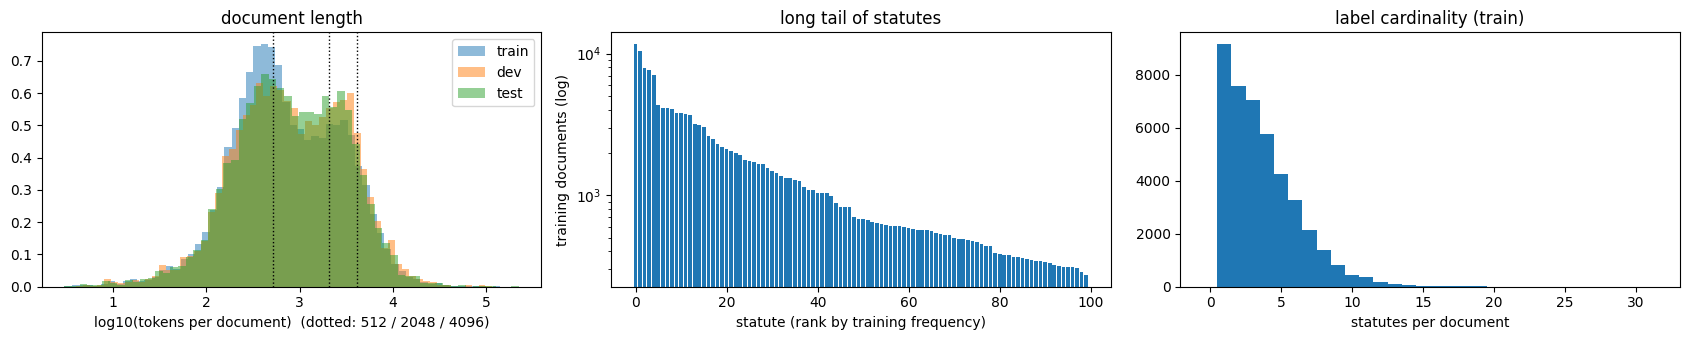

In [22]:
DATA = load_data(merge(DEFAULTS, {"data_dir": str(DATA_DIR), "out_dir": OUT_DIR, "cache_dir": CACHE_DIR, "max_docs": MAX_DOCS,
                                  "backbone": {"ckpt": FOUND.get("A2") or next(iter(FOUND.values()))}}))
print(f"label space: {len(DATA['space'])} statute ids ({DATA['space'][0]} .. {DATA['space'][-1]})")
if RUN_EDA:
    D.describe_raw(DATA_DIR)
    ST = D.stats(DATA)
    print(json.dumps(ST, indent=1))
    import numpy as np, matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.5))
    for split in ("train", "dev", "test"):
        ax[0].hist(np.log10([max(1, len(t)) for t in DATA[split]["tokens"]]), bins=60, alpha=0.5, label=split, density=True)
    for L in (512, 2048, 4096):
        ax[0].axvline(np.log10(L), color="k", ls=":", lw=1)
    ax[0].set_xlabel("log10(tokens per document)  (dotted: 512 / 2048 / 4096)"); ax[0].legend(); ax[0].set_title("document length")
    f = np.sort(DATA["train"]["Y"].sum(0))[::-1]
    ax[1].bar(range(len(f)), f); ax[1].set_yscale("log"); ax[1].set_xlabel("statute (rank by training frequency)")
    ax[1].set_ylabel("training documents (log)"); ax[1].set_title("long tail of statutes")
    card = DATA["train"]["Y"].sum(1).astype(int)
    ax[2].hist(card, bins=np.arange(card.max() + 2) - 0.5); ax[2].set_xlabel("statutes per document"); ax[2].set_title("label cardinality (train)")
    plt.tight_layout(); plt.show()

## Build the job list

In [23]:
def run_name(n):
    return n + TAG + ("_smoke" if SMOKE_TEST else "")

JOBS = []
for name in RUN_LIST:
    cfg = json.loads(json.dumps(EXPERIMENTS[name]))
    cfg.update(run_name=run_name(name), data_dir=str(DATA_DIR), out_dir=OUT_DIR, ckpt_root=CKPT_ROOT,
               cache_dir=CACHE_DIR, max_docs=MAX_DOCS)
    key = cfg["backbone"]["ckpt"].lstrip("@")
    if key not in FOUND:
        print(f"SKIP {name}: checkpoint @{key} not attached"); continue
    cfg["backbone"]["ckpt"] = FOUND[key]
    teacher = None
    if cfg.get("kd", {}).get("teacher_run"):
        teacher = run_name(os.path.basename(cfg["kd"]["teacher_run"]))
        cfg["kd"]["teacher_run"] = os.path.join(OUT_DIR, teacher)
        if teacher not in [run_name(n) for n in RUN_LIST] and not os.path.exists(os.path.join(OUT_DIR, teacher, "summary.json")):
            print(f"SKIP {name}: teacher {teacher} is neither in RUN_LIST nor finished earlier"); continue
    cfg.setdefault("train", {})["max_minutes"] = MAX_MINUTES
    for k, v in OVERRIDES.items():
        set_by_path(cfg, k, json.dumps(v))
    if SMOKE_TEST:
        cfg["backbone"]["keep_layers"] = 1 if not cfg["backbone"].get("keep_layers") else 2
        cfg["train"].update(epochs=1, docs_per_epoch=8)
    JOBS.append((cfg["run_name"], cfg, teacher))
for n, c, t in JOBS:
    ch = merge(DEFAULTS["chunks"], c.get("chunks", {}))
    hd = merge(DEFAULTS["head"], c.get("head", {})); ls = merge(DEFAULTS["loss"], c.get("loss", {}))
    print(f"  {n:28s} model {os.path.basename(os.path.dirname(c['backbone']['ckpt'])):22s} method {c['method']['name']:8s} "
          f"chunks {ch['k']}x{ch['len']} {ch['strategy']:8s} head {hd['agg']:10s} loss {ls['name']}" + (f"  (teacher {t})" if t else ""))

  T1_A2_full_hier              model A_llama_decoder_v2     method full     chunks 4x512 headtail head attn       loss bce
  R2_B_full_hier               model B_encoder_decoder      method full     chunks 4x512 headtail head attn       loss bce
  R1_A2_lorma_hier             model A_llama_decoder_v2     method lorma    chunks 4x512 headtail head attn       loss bce
  R3_C_partial_hier            model C_hybrid_prefix_mlm    method partial  chunks 4x512 headtail head attn       loss bce
  R4_KD_D6L_from_T1            model D_efficient_swa_mqa    method full     chunks 4x1024 headtail head attn       loss bce  (teacher T1_A2_full_hier)
  X1_D6L_noKD                  model D_efficient_swa_mqa    method full     chunks 4x1024 headtail head attn       loss bce
  X2_A2_full_lwan              model A_llama_decoder_v2     method full     chunks 4x512 headtail head label_attn loss bce
  X3_A2_qlora_hier             model A_llama_decoder_v2     method qlora    chunks 4x512 headtail head attn   

## Run (parallel on 2 GPUs, otherwise sequential)

In [24]:
import time, traceback
os.makedirs(f"{OUT_DIR}/_jobs", exist_ok=True); os.makedirs(f"{OUT_DIR}/_logs", exist_ok=True)
KEEP = ("[epoch]", "[submit]", "[kd]", "[train]", "[model]", "[dev]", "[progress]", "early stop", "Error", "Traceback")

def finished(name):
    return os.path.exists(os.path.join(OUT_DIR, name, "summary.json"))

def run_parallel(jobs, gpus):
    pending, running, done, failed = list(jobs), {}, set(), set()
    t0 = time.time()
    while pending or running:
        for g in gpus:
            if g in running:
                continue
            for j in list(pending):
                name, cfg, teacher = j
                if teacher and teacher in failed:
                    print(f"SKIP {name}: teacher {teacher} failed"); pending.remove(j); failed.add(name); continue
                if teacher and not finished(teacher):
                    continue
                path = f"{OUT_DIR}/_jobs/{name}.json"
                json.dump(cfg, open(path, "w"), indent=1)
                log = open(f"{OUT_DIR}/_logs/{name}.log", "w")
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g), PYTHONUNBUFFERED="1")
                proc = subprocess.Popen([sys.executable, "-u", "-m", "p5lsi.run", "--config", path],
                                        cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[g] = (name, proc, log, 0)
                pending.remove(j)
                print(f"[{time.time()-t0:6.0f}s] START {name} on GPU {g}")
                break
        time.sleep(15)
        for g, (name, proc, log, pos) in list(running.items()):
            txt = open(f"{OUT_DIR}/_logs/{name}.log").read()
            for line in txt[pos:].splitlines():
                if any(k in line for k in KEEP):
                    print(f"  [{name} @GPU{g}] {line}")
            running[g] = (name, proc, log, len(txt))
            if proc.poll() is not None:
                log.close(); del running[g]
                if proc.returncode == 0 and finished(name):
                    done.add(name); print(f"[{time.time()-t0:6.0f}s] DONE  {name}")
                else:
                    failed.add(name); print(f"[{time.time()-t0:6.0f}s] FAILED {name} (exit {proc.returncode}); log tail:")
                    print("\n".join(txt.splitlines()[-25:]))
        if pending and not running and all(t and not finished(t) for _, _, t in pending):
            for n, _, t in pending:
                print(f"SKIP {n}: teacher {t} never finished")
            break
    return done, failed

if PARALLEL and N_GPU >= 2:
    DONE, FAILED = run_parallel(JOBS, list(range(N_GPU)))
else:
    DONE, FAILED = set(), set()
    for name, cfg, teacher in JOBS:
        if teacher and not finished(teacher):
            print(f"SKIP {name}: teacher {teacher} not finished"); continue
        print(f"\n##################### {name} #####################")
        try:
            summary, model = run(cfg, data=DATA); del model; torch.cuda.empty_cache(); DONE.add(name)
        except Exception:
            traceback.print_exc(); FAILED.add(name)
            print(f">>> {name} FAILED; continuing")

os.makedirs(f"{WORK}/submissions", exist_ok=True)
for name in sorted(DONE):
    if name.endswith("_smoke"):
        continue
    s = json.load(open(os.path.join(OUT_DIR, name, "summary.json")))
    if s.get("submission"):
        shutil.copy(s["submission"], f"{WORK}/submissions/{name}.zip")
print("done:", sorted(DONE), "| failed:", sorted(FAILED))
print("submissions:", sorted(os.listdir(f"{WORK}/submissions")))

[     0s] START T1_A2_full_hier on GPU 0
[     0s] START R2_B_full_hier on GPU 1
  [T1_A2_full_hier @GPU0] [model] arch A (LlamaLM) | layers 11/11 | attention bidirectional | method full | chunks 4x512 headtail | head attn/attn | loss bce
  [T1_A2_full_hier @GPU0] [model] params total 93.98M | trainable 93.984M (100.0%)
  [T1_A2_full_hier @GPU0] [train] 4 epochs x 10000 documents | ~2.27 chunks/doc | 1250 steps/epoch | 5000 steps | amp torch.float16 | time limit 70 min
  [R2_B_full_hier @GPU1] [model] arch B (EncDecLM) | layers 6/6 | attention bidirectional | method full | chunks 4x512 headtail | head attn/attn | loss bce
  [R2_B_full_hier @GPU1] [model] params total 42.47M | trainable 42.465M (100.0%)
  [R2_B_full_hier @GPU1] [train] 4 epochs x 10000 documents | ~2.27 chunks/doc | 1250 steps/epoch | 5000 steps | amp torch.float16 | time limit 70 min
  [R2_B_full_hier @GPU1] [progress] epoch 1  20% | loss 13.3836 | 0.8 min | ETA all epochs 15.4 min
  [R2_B_full_hier @GPU1] [progress] e

## Results table (also saved as `/kaggle/working/RESULTS.csv`)

In [25]:
import csv
import pandas as pd
rows = []
for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
    s = json.load(open(p))
    if SMOKE_TEST != s["run"].endswith("_smoke"):
        continue
    m, ch, dc = s["method"], s["chunks"], s["dev_calibrated"]
    rows.append({"run": s["run"], "arch": s["arch"], "backbone": s["backbone"], "layers": s["layers"],
                 "method": m["name"] + ("+KD" if s.get("kd_teacher") else ""),
                 "doc_repr": f"{ch['k']}x{ch['len']} {ch['strategy']}", "head": f"{s['head']['chunk_pool']}/{s['head']['agg']}",
                 "loss": s["loss"]["name"], "params_M": round(s["params_total"] / 1e6, 1),
                 "trainable_M": round(s["params_trainable"] / 1e6, 3), "trainable_%": s["trainable_pct"],
                 "train_min": s["train_minutes"], "epochs": s["epochs_run"], "best_epoch": s["best_epoch"],
                 "peak_mem_GB": round(s["peak_train_mem_gb"] or 0, 2), "docs_per_s": s["infer_docs_per_sec"],
                 "dev_F1@0.5": round(s["dev_at_0.5"]["macro_f1"], 4), "thr": s["threshold_strategy"],
                 "dev_macroF1_cf": round(s["crossfit_macro_f1"][s["threshold_strategy"]], 4),
                 "dev_macroF1": round(dc["macro_f1"], 4), "dev_macroP": round(dc["macro_p"], 4), "dev_macroR": round(dc["macro_r"], 4),
                 "dev_microF1": round(dc["micro_f1"], 4), "dev_subset_acc": round(dc["subset_acc"], 4),
                 "dev_pred/doc": round(dc["pred_per_doc"], 2), "test_pred/doc": s.get("test_pred_per_doc")})
if rows:
    with open(f"{WORK}/RESULTS.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    RES = pd.DataFrame(rows).sort_values("dev_macroF1_cf", ascending=False)
    display(RES)
    print("threshold strategies (cross-fitted dev macro-F1):")
    for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
        s = json.load(open(p))
        if SMOKE_TEST == s["run"].endswith("_smoke"):
            print(f"  {s['run']:28s}", {k: round(v, 4) for k, v in s["crossfit_macro_f1"].items()}, "->", s["threshold_strategy"])

,run,arch,backbone,layers,method,doc_repr,head,loss,params_M,trainable_M,...,dev_F1@0.5,thr,dev_macroF1_cf,dev_macroF1,dev_macroP,dev_macroR,dev_microF1,dev_subset_acc,dev_pred/doc,test_pred/doc
4,T1_A2_full_hier,A,A_llama_decoder_v2,11,full,4x512 headtail,attn/attn,bce,94.0,93.984,...,0.2552,per_label,0.3826,0.3995,0.3989,0.4287,0.4939,0.0451,4.88,4.765
6,X2_A2_full_lwan,A,A_llama_decoder_v2,11,full,4x512 headtail,attn/label_attn,bce,94.0,93.955,...,0.2534,per_label,0.3821,0.3991,0.3984,0.4277,0.4941,0.0410,4.84,4.742
3,R4_KD_D6L_from_T1,D,D_efficient_swa_mqa,6,full+KD,4x1024 headtail,attn/attn,bce,46.0,45.955,...,0.2399,per_label,0.3774,0.3936,0.3965,0.4177,0.4921,0.0413,4.81,4.720
7,X3_A2_qlora_hier,A,A_llama_decoder_v2,11,qlora,4x512 headtail,attn/attn,bce,96.1,2.302,...,0.2354,per_label,0.3723,0.3904,0.3938,0.4130,0.4888,0.0417,4.81,4.704
8,X4_A2_full_asl,A,A_llama_decoder_v2,11,full,4x512 headtail,attn/attn,asl,94.0,93.984,...,0.3541,per_label,0.3722,0.3917,0.3938,0.4226,0.4889,0.0396,5.04,4.914
5,X1_D6L_noKD,D,D_efficient_swa_mqa,6,full,4x1024 headtail,attn/attn,bce,46.0,45.955,...,0.2336,per_label,0.3640,0.3826,0.3830,0.4171,0.4724,0.0334,5.04,4.912
0,R1_A2_lorma_hier,A,A_llama_decoder_v2,11,lorma,4x512 headtail,attn/attn,bce,95.2,1.400,...,0.2250,per_label,0.3634,0.3806,0.3747,0.4177,0.4745,0.0359,5.14,5.033
2,R3_C_partial_hier,C,C_hybrid_prefix_mlm,10,partial,4x512 headtail,attn/attn,bce,70.2,19.984,...,0.2243,per_label,0.3607,0.3805,0.3905,0.4039,0.4802,0.0384,4.91,4.804
1,R2_B_full_hier,B,B_encoder_decoder,6,full,4x512 headtail,attn/attn,bce,42.5,42.465,...,0.1701,per_label,0.3158,0.3317,0.3211,0.3921,0.4174,0.0216,5.89,5.732
9,X5_B_adapter_hier,B,B_encoder_decoder,6,adapter,4x512 headtail,attn/attn,bce,43.4,1.030,...,0.0803,per_label,0.2388,0.2527,0.2191,0.3575,0.3391,0.0037,7.78,7.601


threshold strategies (cross-fitted dev macro-F1):
  R1_A2_lorma_hier             {'fixed': 0.2245, 'global': 0.3467, 'per_label': 0.3634} -> per_label
  R2_B_full_hier               {'fixed': 0.1697, 'global': 0.2867, 'per_label': 0.3158} -> per_label
  R3_C_partial_hier            {'fixed': 0.224, 'global': 0.3487, 'per_label': 0.3607} -> per_label
  R4_KD_D6L_from_T1            {'fixed': 0.2393, 'global': 0.3584, 'per_label': 0.3774} -> per_label
  T1_A2_full_hier              {'fixed': 0.2549, 'global': 0.3643, 'per_label': 0.3826} -> per_label
  X1_D6L_noKD                  {'fixed': 0.2332, 'global': 0.3483, 'per_label': 0.364} -> per_label
  X2_A2_full_lwan              {'fixed': 0.2529, 'global': 0.3653, 'per_label': 0.3821} -> per_label
  X3_A2_qlora_hier             {'fixed': 0.2349, 'global': 0.3522, 'per_label': 0.3723} -> per_label
  X4_A2_full_asl               {'fixed': 0.3537, 'global': 0.3537, 'per_label': 0.3722} -> per_label
  X5_B_adapter_hier            {'fixed': 0.

## Ensemble → one more submission

In [26]:
if ENSEMBLE == "auto":
    members = list(RES["run"][:3]) if rows else []
else:
    members = [run_name(n) for n in ENSEMBLE]
members = [m for m in members if finished(m)]
if len(members) >= 2:
    es = ensemble([f"{OUT_DIR}/{r}" for r in members], f"{OUT_DIR}/ENS{TAG}" + ("_smoke" if SMOKE_TEST else ""), DATA)
    print("ensemble", members, "| dev macro-F1 (cross-fitted)", round(es["crossfit_macro_f1"][es["threshold_strategy"]], 4),
          "| thresholds", es["threshold_strategy"])
    if not SMOKE_TEST:
        shutil.copy(es["submission"], f"{WORK}/submissions/ENS{TAG}.zip")
else:
    print("ensemble skipped (needs >= 2 finished members); members:", members)

ensemble of ['T1_A2_full_hier', 'X2_A2_full_lwan', 'R4_KD_D6L_from_T1'] | thresholds 'per_label' | cross-fitted {'fixed': 0.2478919821067191, 'global': 0.36742874281216553, 'per_label': 0.3887305684924951}
macro-F1 0.4053 (P 0.4028 R 0.4353) | macro-F1 over the 100 gold-present labels 0.4053 | micro-F1 0.4976 (P 0.4466 R 0.5618) | subset acc 0.0442 | statutes/doc gold 3.92 pred 4.93 | 10181 docs x 100 labels
ensemble ['T1_A2_full_hier', 'X2_A2_full_lwan', 'R4_KD_D6L_from_T1'] | dev macro-F1 (cross-fitted) 0.3887 | thresholds per_label


## Which parts of a document identify the statutes? (section analysis)

In [27]:
import pandas as pd
SEC = {}
for n in SECTION_RUNS:
    r = run_name(n)
    if not finished(r):
        print("skip", r, "(not finished)"); continue
    SEC[r] = section_analysis(f"{OUT_DIR}/{r}", DATA, "cuda" if N_GPU else "cpu", max_docs=SECTION_MAX_DOCS)
    print(r); display(pd.DataFrame(SEC[r]["views"]))
    att = SEC[r]["chunk_attention_by_position(uniform 8 chunks)"]
    if att:
        print("chunk attention by relative position:", att)

T1_A2_full_hier


,view,chunks,macro_f1,micro_f1,subset_acc,pred_per_doc
0,first 512 (head),1 x 512 head,0.3567,0.4523,0.0340,5.67
1,middle 512,1 x 512 middle,0.3454,0.4447,0.0447,4.43
2,last 512 (tail),1 x 512 tail,0.3529,0.4438,0.0353,5.47
3,head 2 chunks,2 x 512 head,0.3867,0.4852,0.0440,5.02
4,tail 2 chunks,2 x 512 tail,0.3794,0.4745,0.0467,4.93
5,trained view,4 x 512 headtail,0.4028,0.4977,0.0540,4.85
6,uniform 4 chunks,4 x 512 uniform,0.3903,0.4920,0.0540,4.76
7,uniform 8 chunks,8 x 512 uniform,0.3924,0.4945,0.0547,4.54


chunk attention by relative position: {'0.00-0.12': 1.257, '0.12-0.25': 1.153, '0.25-0.38': 1.166, '0.38-0.50': 1.132, '0.50-0.62': 0.996, '0.62-0.75': 0.896, '0.75-0.88': 0.844, '0.88-1.00': 0.733}


## Per-statute analysis of the best run (or set `RUN`): rare statutes, missed and confused statutes

T1_A2_full_hier
dev, thresholds 'per_label'
macro-F1 0.3995 (P 0.3989 R 0.4287) | macro-F1 over the 100 gold-present labels 0.3995 | micro-F1 0.4939 (P 0.4450 R 0.5547) | subset acc 0.0451 | statutes/doc gold 3.92 pred 4.88 | 10181 docs x 100 labels

macro-F1 by training frequency of the statute:


,train_docs,labels,macro_f1,macro_p,macro_r,dev_gold
0,"[100, 500)",30,0.3092,0.3300,0.3311,2904
1,"[500, inf)",70,0.4382,0.4284,0.4706,36962


exact match by number of gold statutes: {'1 statutes': {'docs': 1544, 'subset_acc': 0.0868}, '2 statutes': {'docs': 1904, 'subset_acc': 0.083}, '3 statutes': {'docs': 1818, 'subset_acc': 0.0457}, '4+ statutes': {'docs': 4915, 'subset_acc': 0.0171}}
statutes present in dev but never predicted correctly: 0

worst statutes:


,id,p,r,f1,gold,pred,train_docs
0,2,0.214286,0.061224,0.095238,98,28,367
1,0,0.061728,0.232558,0.097561,86,324,343
2,8,0.062084,0.304348,0.103131,92,451,349
3,99,0.122172,0.153409,0.136020,176,221,674
4,27,0.130081,0.192771,0.155340,83,123,329
5,52,0.111111,0.261029,0.155873,272,639,1084
6,41,0.125654,0.234146,0.163543,205,382,821
7,18,0.179775,0.160000,0.169312,100,89,393
8,9,0.127660,0.262136,0.171701,206,423,823
9,65,0.128889,0.276190,0.175758,105,225,351


most missed (statute, documents): [(5, 817), (39, 690), (43, 631), (12, 516), (97, 487), (13, 481), (44, 442), (10, 434), (14, 427), (34, 389)]
most false positives (statute, documents): [(97, 2269), (43, 1817), (5, 1676), (39, 1011), (51, 875), (63, 772), (44, 768), (10, 747), (45, 627), (52, 568)]
confused pairs (gold missed -> predicted instead, documents): [[[12, 5], 182], [[14, 5], 179], [[13, 5], 173], [[39, 97], 171], [[5, 97], 137], [[94, 97], 129], [[77, 97], 128], [[54, 97], 126], [[39, 43], 125], [[39, 5], 120]]


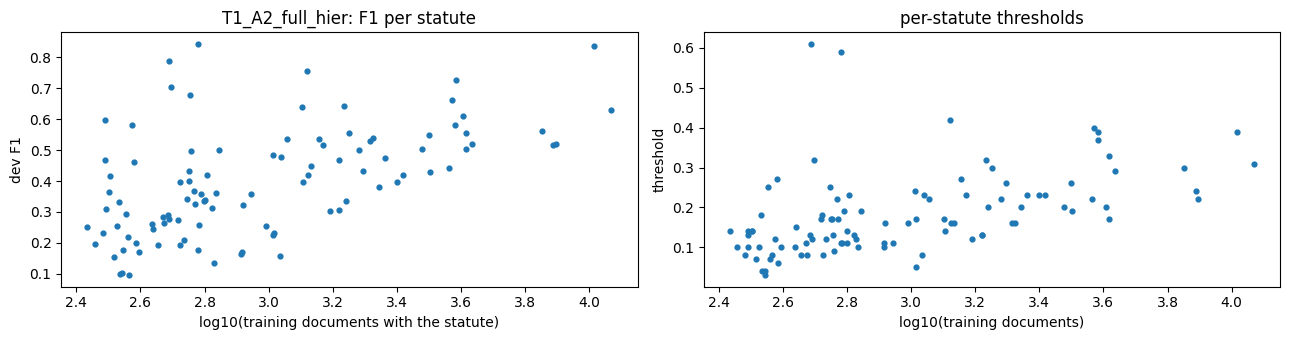

In [28]:
RUN = RES.iloc[0]["run"] if rows else None
if RUN:
    import numpy as np
    import matplotlib.pyplot as plt
    from p5lsi.metrics import format_report
    rep = json.load(open(f"{OUT_DIR}/{RUN}/dev_report.json"))
    print(RUN); print(format_report(rep["calibrated"], f"dev, thresholds '{rep['strategy']}'"))
    LA = label_analysis(f"{OUT_DIR}/{RUN}", DATA)
    print("\nmacro-F1 by training frequency of the statute:"); display(pd.DataFrame(LA["f1_by_train_frequency"]))
    print("exact match by number of gold statutes:", LA["exact_match_by_gold_count"])
    print("statutes present in dev but never predicted correctly:", LA["statutes_never_predicted_correctly"])
    print("\nworst statutes:"); display(pd.DataFrame(LA["worst_statutes"]))
    print("most missed (statute, documents):", LA["most_missed"][:10])
    print("most false positives (statute, documents):", LA["most_false_positive"][:10])
    print("confused pairs (gold missed -> predicted instead, documents):", LA["confused_pairs(gold_missed->predicted_instead)"][:10])
    per = pd.DataFrame(rep["calibrated"]["per_label"])
    from collections import Counter
    fr = Counter(s for labs in DATA["train"]["labels"] for s in labs)
    per["train_docs"] = per["id"].map(lambda i: fr.get(i, 0))
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    ax[0].scatter(np.log10(per.train_docs.clip(lower=1)), per.f1, s=12)
    ax[0].set_xlabel("log10(training documents with the statute)"); ax[0].set_ylabel("dev F1"); ax[0].set_title(f"{RUN}: F1 per statute")
    if isinstance(rep["thresholds"], dict):
        th = per["id"].map(lambda i: rep["thresholds"][str(i)])
        ax[1].scatter(np.log10(per.train_docs.clip(lower=1)), th, s=12); ax[1].set_ylabel("threshold")
        ax[1].set_xlabel("log10(training documents)"); ax[1].set_title("per-statute thresholds")
    else:
        ax[1].text(0.1, 0.5, f"global threshold {rep['thresholds']}", fontsize=12); ax[1].axis("off")
    plt.tight_layout(); plt.show()

## Efficiency: model size, memory and inference cost

In [29]:
if rows:
    E = RES[["run", "arch", "method", "layers", "params_M", "trainable_M", "trainable_%", "peak_mem_GB", "train_min",
             "docs_per_s", "dev_macroF1_cf"]].copy()
    best = E.dev_macroF1_cf.max()
    E["F1_vs_best"] = (E.dev_macroF1_cf - best).round(4)
    display(E.sort_values("params_M"))
    for n in RUN_LIST:
        r = run_name(n)
        if finished(r) and os.path.exists(f"{OUT_DIR}/{r}/teacher.json"):
            t = json.load(open(f"{OUT_DIR}/{r}/teacher.json")); s = json.load(open(f"{OUT_DIR}/{r}/summary.json"))
            print(f"KD {r}: student {s['params_total']/1e6:.1f}M params vs teacher {t['teacher_params']/1e6:.1f}M "
                  f"({s['params_total']/t['teacher_params']:.0%}) | dev macro-F1 {s['dev_calibrated']['macro_f1']:.4f} vs teacher "
                  f"{t['teacher_dev_macro_f1']:.4f} | student inference {s['infer_docs_per_sec']} docs/s")

,run,arch,method,layers,params_M,trainable_M,trainable_%,peak_mem_GB,train_min,docs_per_s,dev_macroF1_cf,F1_vs_best
1,R2_B_full_hier,B,full,6,42.5,42.465,100.000,3.57,17.3,138.48,0.3158,-0.0668
9,X5_B_adapter_hier,B,adapter,6,43.4,1.030,2.377,2.47,14.4,133.17,0.2388,-0.1438
3,R4_KD_D6L_from_T1,D,full+KD,6,46.0,45.955,100.000,1.61,31.6,77.37,0.3774,-0.0052
5,X1_D6L_noKD,D,full,6,46.0,45.955,100.000,1.62,32.2,76.03,0.3640,-0.0186
2,R3_C_partial_hier,C,partial,10,70.2,19.984,28.463,2.76,19.6,74.89,0.3607,-0.0219
10,X6_C_lorma_hier,C,lorma,10,71.3,1.218,1.709,6.16,24.7,56.68,0.0802,-0.3024
8,X4_A2_full_asl,A,full,11,94.0,93.984,100.000,8.12,42.9,54.46,0.3722,-0.0104
4,T1_A2_full_hier,A,full,11,94.0,93.984,100.000,8.12,42.1,55.57,0.3826,0.0000
6,X2_A2_full_lwan,A,full,11,94.0,93.955,100.000,8.13,43.2,53.97,0.3821,-0.0005
0,R1_A2_lorma_hier,A,lorma,11,95.2,1.400,1.471,7.23,44.7,42.91,0.3634,-0.0192


KD R4_KD_D6L_from_T1: student 46.0M params vs teacher 94.0M (49%) | dev macro-F1 0.3936 vs teacher 0.3995 | student inference 77.37 docs/s


## Download / submit